# METABRIC IntegrativeVAE RNA-only Representation Learning

This notebook trains a breast-cancer-specific variational autoencoder inspired by the IntegrativeVAEs/CancerAI-CL framework and applies the trained encoder to the institutional oligometastatic/polymetastatic transcriptomic cohort.

The original IntegrativeVAEs work proposed VAE architectures for cancer data integration and applied them to METABRIC breast cancer data using mRNA expression, CNA, and clinical variables.

In this notebook, we start with an RNA-only adaptation because the current downstream representation-learning workflow evaluates transcriptomic TPM-based representations. The goal is to generate a breast-cancer-specific latent transcriptomic representation trained on METABRIC and then project the institutional oligo/poly cohort into this latent space.

The generated latent scores are saved as a CSV file and can then be evaluated in the existing transcriptomic representation-learning notebook using the same nested cross-validation and macro-F1 model-selection criterion as GenomicSuperSignature, MultiPLIER, and Tybalt.

## Expression sources and transfer limitations

The external expression source is cBioPortal study `brca_metabric`: Illumina HT-12 v3 microarray log2 intensities for 1,980 samples across 20,603 gene rows. The institutional matrix contains 139 patients and 18,260 log2-TPM RNA-seq features. These measurements are not equivalent scales; cross-platform domain shift limits transfer of an externally trained encoder.

No joint cohort-wide normalisation is used. Encoder preprocessing is fitted on METABRIC training samples only and frozen before transforming institutional expression. Institutional labels do not enter encoder training. The reduced pickle source is not used for training, gene selection or overlap estimates.


In [ ]:
# Display precision only; analytical values and saved artifacts stay unchanged.
from pathlib import Path as _DisplayPath
import sys as _display_sys
_display_root = _DisplayPath.cwd()
while not (_display_root / "scripts").is_dir() and _display_root != _display_root.parent:
    _display_root = _display_root.parent
if str(_display_root) not in _display_sys.path:
    _display_sys.path.insert(0, str(_display_root))
from scripts.OligoPolyThesis.utils_ml_oligopoly import thesis_display, thesis_print

## Imports ##

import os

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import json
import importlib

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from IPython.display import display, Markdown


Reusable methods are imported from `scripts/OligoPolyThesis/utils_ml_oligopoly.py`.


In [ ]:
import sys
from sklearn.model_selection import StratifiedKFold, train_test_split
ROOT = Path.cwd()
while not (ROOT / "scripts").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from scripts.OligoPolyThesis.utils_ml_oligopoly import (
    begin_metabric_encoder_run, metabric_encoder_operational_callbacks, complete_metabric_encoder_run,
    run_metabric_vae_ig, restore_metabric_ig_l1_model,
    set_global_seed, split_transcriptomics_features_target_metadata,
    scale_external_and_institutional_expression, train_integrativevae_rna_only,
    project_samples_with_z_mean_encoder, save_integrativevae_outputs,
    build_integrativevae_hvae_rna_branch, plot_vae_training_history,
    audit_cbioportal_metabric_overlap, prepare_cbioportal_metabric_transfer,
    summarise_metabric_encoder_history, align_metabric_latent_scores,
    load_metabric_reviewed_scores, metabric_source_fingerprint, evaluate_metabric_latent_representation,
    tpm_outer_splits, validate_tpm_oof, rank_tpm_inner_scores, tpm_pooled_oof_metrics,
    summarise_representation_results, extract_fitted_tpm_feature_rankings,
    plot_roc_curves, plot_precision_recall_curves, plot_confusion_matrix,
    plot_calibration_curve, plot_metric_boxplots,
    compute_representation_silhouette, plot_umap_representation,
    tpm_flaml_settings, fit_metabric_latent_flaml, run_nested_flaml_metabric_latent,
)
from scripts.OligoPolyThesis.utils_ml_oligopoly import (
    plot_latent_outer_scores,
    plot_latent_train_test,
    plot_latent_train_test_folds,
    select_mean_inner_combination,
    display_interpretation,
)


## Reproducibility

Random seeds are fixed to make the VAE training procedure more reproducible.

In [ ]:
RANDOM_STATE = 42
set_global_seed(RANDOM_STATE)
RUN_PREPARE_SOURCE = True
RUN_RNA_ENCODER = False
RUN_HVAE_ENCODER = False
RUN_NESTED_CV = False
RUN_FULL_COHORT_TUNING = False
RUN_FLAML = False
RUN_FULL_COHORT_FLAML = False
RUN_EXPLORATORY = False
RUN_INTERPRETATION = False
RUN_INTEGRATED_GRADIENTS = True
FLAML_TIME_BUDGET_SECONDS = 120
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = "f1_macro"
metabric_registry = {}
if RUN_FLAML or RUN_FULL_COHORT_FLAML:
    tpm_flaml_settings(FLAML_TIME_BUDGET_SECONDS, RANDOM_STATE)


## Define Input and Output Paths

We define the paths to:

1. the METABRIC expression matrix used to train the breast-cancer-specific VAE;
2. the institutional oligo/poly TPM expression matrix that will be projected into the learned latent space;
3. the output directory where the trained model, scaler, selected genes, training history, metadata, and latent scores will be saved.

The METABRIC data are used only for unsupervised representation learning. The institutional oligo/poly labels are not used during VAE training.

In [4]:
project_root = Path("/mnt/data3/MCPP-Breast")
metabric_source_dir = project_root / "Machine-Learning-Models-poly_vs_oligo" / "External-Data" / "cBioPortal" / "brca_metabric"
metabric_expression_path = metabric_source_dir / "data_mrna_illumina_microarray.txt"
metabric_profile_metadata_path = metabric_source_dir / "meta_mrna_illumina_microarray.txt"
institutional_expression_path = project_root / "Transcriptomic-Data" / "Preprocessed" / "transcriptomics_oligo_poly_log2_tpm_preprocessed.csv"
gene_mapping_path = institutional_expression_path.parent / "transcriptomics_feature_name_mapping.csv"
metabric_study_metadata_path = metabric_source_dir / "meta_study.txt"
DUPLICATE_EXPRESSION_AGGREGATION = "mean"
source_paths = [metabric_study_metadata_path, metabric_expression_path, metabric_profile_metadata_path, institutional_expression_path, gene_mapping_path]
output_dir = project_root / "Machine-Learning-Models-poly_vs_oligo" / "Transcriptomics-Representation-Learning" / "METABRIC-IntegrativeVAE" / "cBioPortal-reviewed" / "canonical-16950"
hvae_output_dir = output_dir / "Original-HVAE-RNA-Branch"
source_provenance_path = output_dir / "metabric_cbioportal_source_provenance.json"
thesis_print("Required source:", metabric_expression_path)
thesis_print("Output directory:", output_dir)


Required source: /mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/External-Data/cBioPortal/brca_metabric/data_mrna_illumina_microarray.txt
Output directory: /mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/Transcriptomics-Representation-Learning/METABRIC-IntegrativeVAE/cBioPortal-reviewed/canonical-16950


## METABRIC Source Provenance

The expression source is the native mRNA-expression profile of cBioPortal study `brca_metabric`, stored under `/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/External-Data/cBioPortal/brca_metabric/`:

- `data_mrna_illumina_microarray.txt`: 20,603 gene rows; `Hugo_Symbol` and `Entrez_Gene_Id` followed by 1,980 sample columns.
- `meta_mrna_illumina_microarray.txt`: continuous Illumina HT-12 v3 microarray log2 intensity measurements.
- `meta_study.txt`: study identifier and publication provenance.

Values are not TPM or diploid-reference z-scores and must not receive another log transform. No reduced pickle source is used as a fallback. The microarray/RNA-seq measurement difference remains a cross-platform transfer limitation.


In [5]:
source_available = all(p.exists() for p in [metabric_expression_path, metabric_profile_metadata_path, metabric_study_metadata_path])
thesis_print("Complete source files present:", source_available)
if not source_available:
    thesis_print("The complete cBioPortal expression payload and profile metadata are not available.")
    if any([RUN_PREPARE_SOURCE, RUN_RNA_ENCODER, RUN_HVAE_ENCODER, RUN_NESTED_CV,
            RUN_FULL_COHORT_TUNING, RUN_FLAML, RUN_FULL_COHORT_FLAML, RUN_EXPLORATORY, RUN_INTERPRETATION]):
        raise FileNotFoundError("The canonical analysis requires the complete cBioPortal METABRIC source.")


Complete source files present: True


## Configuration

The RNA-only latent dimension (100), architectures, learning rates and external top-variable-gene budget (1,000) are fixed. The full METABRIC source supplies the candidate genes without expanding the encoder input budget. Gene variance and missing-value medians are learned from the METABRIC training partition only, before validation-loss monitoring. Neither institutional labels nor institutional expression values rank encoder genes.


In [ ]:
## Configuration ##

SAMPLE_ID_CANDIDATES = [
    "sample_id_normalised",
    "sample_id",
    "sample",
    "Sample",
    "barcode",
    "patient_id",
    "PATIENT_ID",
]

N_TOP_VARIABLE_GENES = 1000
LATENT_DIM = 100

VALIDATION_FRACTION = 0.2
BATCH_SIZE = 32
EPOCHS = 300
PATIENCE = 25

HIDDEN_DIMS = (1024, 256)
DROPOUT_RATE = 0.2
LEARNING_RATE = 1e-3
BETA = 1.0

SCALER_TYPE = "standard"

# Set to True only if the METABRIC values are not already log-transformed.
APPLY_LOG2_TO_METABRIC = False

# The institutional file name suggests it is already log2(TPM + 1) preprocessed.
APPLY_LOG2_TO_INSTITUTIONAL = False

REPRESENTATION_NAME = "metabric_cbioportal_integrativevae_rna_only_latent100"
rna_completed_dir = output_dir / f"{REPRESENTATION_NAME}_completed"
latent_scores_path = rna_completed_dir / f"transcriptomics_{REPRESENTATION_NAME}_scores.csv"
rna_history_path = rna_completed_dir / f"{REPRESENTATION_NAME}_training_history.csv"


## Source Loading

The complete gene-row TSV is loaded during preparation, with source validation, identifier harmonisation and overlap calculation performed together.


In [ ]:
thesis_print("Full METABRIC source loading is controlled by RUN_PREPARE_SOURCE or an encoder-training flag.")


## Load Institutional Oligo/Poly TPM Data

We load the institutional preprocessed transcriptomic matrix.

This dataset is projected into the METABRIC-trained latent space but is not used to train the VAE.

In [8]:
institutional_df = pd.read_csv(institutional_expression_path)
institutional_expression_df, y, metadata_df, feature_cols, _ = split_transcriptomics_features_target_metadata(
    institutional_df, target_col="Polymetastatic", feature_prefix="transcriptomics__")
if institutional_expression_df.shape != (139, 18260):
    raise ValueError("Canonical institutional matrix dimensions changed; check cohort/input consistency.")
institutional_expression_df.index = metadata_df.sample_id_normalised.to_numpy()
if metadata_df.sample_id_normalised.isna().any() or metadata_df.sample_id_normalised.duplicated().any():
    raise ValueError("Unique institutional sample identifiers are required.")
outer_splits = tpm_outer_splits(outer_cv, institutional_expression_df, y)
thesis_print(institutional_expression_df.shape)
thesis_display(y.value_counts().sort_index())


(139, 18260)


Polymetastatic
0    54
1    85
Name: count, dtype: int64

### Institutional preprocessing and shared outer patients

`20260707-preprocessing-tpm-oligopolypatients.ipynb`, cells 28–30, applies `log2(TPM + 1)` and retains genes with **TPM ≥1 in at least five patients**. This reduces 19,434 to 18,260 genes using pooled expression values only; no outcome labels enter the prevalence filter. Because the filter is not fitted separately within CV, held-out samples influence which genes are available. This is a transductive preprocessing limitation, not supervised target leakage, and it also applies to the `20260710` benchmark. Its effect on the nested-CV estimates cannot be quantified from these analyses and has not been shown to be material. The established 18,260-gene input is therefore retained, with this caveat stated explicitly.

This notebook reads that same file and patient order, then freezes five stratified splits with seed 42. This reproduces the benchmark's split rule without altering its cohort. Every latent matrix must cover exactly those patient IDs and is aligned to that order; missing or extra patients cause an error. A differently filtered cohort requires a separate comparison, not forced reuse of indices.


## Local Identifier Mapping

The cached preprocessing mapping links institutional model-feature names and Ensembl IDs to source gene symbols. METABRIC supplies symbols and Entrez identifiers. Ensembl version suffixes are stripped only for valid Ensembl syntax; dots in ordinary symbols are preserved. Local Ensembl/Entrez-to-symbol evidence is combined before intersection. Conflicting aliases are reported and excluded, never resolved by taking the first row. Current HGNC alias status cannot be inferred from these source annotations alone.


In [9]:
gene_mapping_df = pd.read_csv(gene_mapping_path)
thesis_display(gene_mapping_df.head())
thesis_print("Cached institutional mapping records:", len(gene_mapping_df))


,model_feature_name,ensembl_gene_id,gene_name
0,transcriptomics__ENSG00000000003,ENSG00000000003,TSPAN6
1,transcriptomics__ENSG00000000005,ENSG00000000005,TNMD
2,transcriptomics__ENSG00000000419,ENSG00000000419,DPM1
3,transcriptomics__ENSG00000000457,ENSG00000000457,SCYL3
4,transcriptomics__ENSG00000000460,ENSG00000000460,FIRRM


Cached institutional mapping records: 18260


## Institutional Identifier Quality Control

The retained institutional identifiers, including unresolved identifiers and duplicate groups, are checked before calculating external overlap.


In [10]:
source_audit = audit_cbioportal_metabric_overlap(
    metabric_expression_path, metabric_profile_metadata_path, metabric_study_metadata_path,
    institutional_expression_df, gene_mapping_df)
institutional_id_audit_df = source_audit['institutional_identifiers']
institutional_id_summary = source_audit['institutional_summary']
thesis_display(pd.DataFrame([source_audit['external_summary'], institutional_id_summary],
                     index=['METABRIC', 'institutional']))
thesis_print(source_audit['source'])


,original_genes,mapped_records,harmonised_genes,duplicate_groups,collapsed_records,unresolved_ids,ambiguous_ids
METABRIC,20603,20208,20001,189,207,0,395
institutional,18260,18260,18260,0,0,0,0


{'gene_rows': 20603, 'samples': 1980, 'total_columns': 1982, 'missing_values': 16, 'infinite_values': 0, 'constant_gene_rows': 0, 'duplicated_sample_ids': 0, 'gene_name': {'valid': 20603, 'missing': 0, 'unique': 20385, 'duplicate_groups': 199, 'duplicate_excess_rows': 218}, 'entrez_gene_id': {'valid': 20603, 'missing': 0, 'unique': 20192, 'duplicate_groups': 380, 'duplicate_excess_rows': 411}}


## Duplicate Expression Records

Resolved METABRIC rows mapping to the same biological gene are averaged per sample on the supplied log2-intensity scale. This combines 189 duplicate groups and removes 207 excess resolved rows without arbitrary first-row selection. Missing measurements are ignored when other values in a group are available; remaining missing values are imputed using the corresponding METABRIC training-partition median. The institutional mappings are unique and undergo no aggregation.

The source lacks probe identifiers, so distinct probes cannot be distinguished reliably from repeated annotations. Mean aggregation is a measurement-combination rule, not a claim of equivalent measurement scales across cohorts.


In [11]:
thesis_display(institutional_id_audit_df.loc[institutional_id_audit_df.status.ne("resolved")])
thesis_display(institutional_id_audit_df.loc[institutional_id_audit_df.duplicate_group_size.gt(1)])


,source_position,original_identifier,supplied_identifiers,gene_symbol,namespace,status,duplicate_group_size


,source_position,original_identifier,supplied_identifiers,gene_symbol,namespace,status,duplicate_group_size


## Cross-dataset Gene Overlap

The canonical aligned space contains 16,950 biological genes in identical sorted order for 1,980 METABRIC samples and 139 institutional patients. It retains 92.83% of institutional genes and 84.75% of unambiguously harmonised METABRIC genes. Conflicting identifier evidence excludes 395 external rows.

The complete aligned space is materialised separately from model-facing inputs. Both encoder variants retain the prespecified 1,000-gene budget, selected by variance in METABRIC training samples only.


In [12]:
thesis_display(pd.DataFrame([source_audit['overlap']]))
thesis_display(source_audit['external_identifiers'].loc[
    lambda frame: frame.status.ne('resolved') | frame.duplicate_group_size.gt(1)])
thesis_print("This identifier check does not aggregate duplicate expression values.")


,common_genes,percent_original_institutional,percent_mapped_institutional,percent_harmonised_metabric,percent_original_metabric_rows
0,16950,92.8,92.8,84.7,82.3


,source_position,original_identifier,supplied_identifiers,gene_symbol,namespace,status,duplicate_group_size
31,31,source_row_31,LINC00937;389634,LINC00937,entrez,resolved,3
34,34,source_row_34,HERC2P9;440248,HERC2P9,entrez,resolved,2
65,65,source_row_65,CASC2;255082,CASC2,entrez,resolved,2
88,88,source_row_88,PDXDC2P-NPIPB14P;283970,PDXDC2P-NPIPB14P,entrez,resolved,3
89,89,source_row_89,RBMY1F;159163,RBMY1F,entrez,resolved,2
...,...,...,...,...,...,...,...
20438,20438,source_row_20438,C5orf60;285679,C5orf60,entrez,resolved,2
20471,20471,source_row_20471,HERC2P3;283755,HERC2P3,entrez,resolved,2
20477,20477,source_row_20477,LOC644662;644662,None,entrez,ambiguous,0
20498,20498,source_row_20498,CCL28;56477,None,entrez,ambiguous,0


This identifier check does not aggregate duplicate expression values.


## External Encoder Preprocessing

METABRIC is split into 1,584 training and 396 validation samples using a shuffled 80:20 split with seed 42. Per-gene imputation medians and the ranking of the 1,000 most variable genes are fitted on training samples only. The complete 16,950-gene aligned space, selected gene order, partitions and preprocessing parameters have source/feature fingerprints.

The RNA-only VAE applies a StandardScaler fitted on the selected METABRIC training matrix. The HVAE branch applies training-fitted per-gene min–max scaling without clipping. Each frozen transformation is applied to METABRIC validation samples and institutional expression. Microarray log2 intensities and RNA-seq log2-TPM remain different measurement domains; scaling does not make the two platforms equivalent.

Encoder fitting and early stopping use METABRIC alone. Institutional labels are used only for subsequent supervised evaluation. Frozen latent means are generated before institutional model fitting, so the external encoder is not retrained within institutional CV folds. No institutional expression statistics are fitted for encoder preparation; the fixed gene schema is used only for alignment.


In [13]:
prepared = None
if RUN_PREPARE_SOURCE or RUN_RNA_ENCODER or RUN_HVAE_ENCODER:
    if APPLY_LOG2_TO_METABRIC or APPLY_LOG2_TO_INSTITUTIONAL:
        raise ValueError("Both selected inputs are already log transformed; additional log transforms are invalid.")
    prepared = prepare_cbioportal_metabric_transfer(
        metabric_expression_path, metabric_profile_metadata_path, institutional_expression_df,
        gene_mapping_df, output_dir, source_paths, n_top_genes=N_TOP_VARIABLE_GENES,
        random_state=RANDOM_STATE, validation_fraction=VALIDATION_FRACTION,
        study_path=metabric_study_metadata_path, duplicate_aggregation=DUPLICATE_EXPRESSION_AGGREGATION)
    metabric_selected_df = prepared["external_selected"]
    institutional_selected_df = prepared["institutional_selected"]
    selected_genes_df = prepared["selected_genes"]
    overlap_summary_df = prepared["overlap_summary"]
    thesis_display(overlap_summary_df, selected_genes_df.head(20))
else:
    thesis_print("Source preparation disabled; encoder inputs have not been recomputed.")


,dataset,original_genes,mapped_records,harmonised_genes,duplicate_groups,collapsed_records,unresolved_ids,ambiguous_ids,common_genes_after_harmonisation,fraction_institutional_harmonised_genes_shared,fraction_original_institutional_genes_shared
0,METABRIC,20603,20208,20001,189,207,0,395,16950,0.928,0.928
1,institutional,18260,18260,18260,0,0,0,0,16950,0.928,0.928


,gene,external_train_variance,external_train_imputation_median
0,SCGB2A2,9.373,11.242
1,MUCL1,8.750,8.354
2,SCGB1D2,8.670,8.164
3,PIP,8.449,10.822
4,TFF1,7.430,9.146
5,ANKRD30A,7.249,10.612
6,HLA-DRB5,6.470,5.468
7,TFF3,5.952,12.474
8,CPB1,5.937,6.012
9,CLEC3A,5.680,5.775


## Scale Expression Matrices

The scaler is fitted only on the METABRIC training split and then applied to both METABRIC validation data and the institutional cohort.

This preserves the transfer-learning setup: METABRIC defines the latent representation space, and the institutional cohort is projected into that space.

In [14]:
if prepared is not None:
    ## Scale Expression Data ##

    scaled_data = scale_external_and_institutional_expression(
        external_selected_df=metabric_selected_df,
        institutional_selected_df=institutional_selected_df,
        validation_fraction=VALIDATION_FRACTION,
        random_state=RANDOM_STATE,
        scaler_type=SCALER_TYPE,
    )

    X_metabric_train = scaled_data["X_external_train"]
    X_metabric_val = scaled_data["X_external_val"]
    X_metabric_full = scaled_data["X_external_full"]
    X_institutional = scaled_data["X_institutional"]
    scaler = scaled_data["scaler"]

    thesis_print("Scaled METABRIC train shape:")
    thesis_print(X_metabric_train.shape)

    thesis_print("\nScaled METABRIC validation shape:")
    thesis_print(X_metabric_val.shape)

    thesis_print("\nScaled institutional shape:")
    thesis_print(X_institutional.shape)
else:
    thesis_print("Stage disabled; no output generated.")


Scaled METABRIC train shape:
(1584, 1000)

Scaled METABRIC validation shape:
(396, 1000)

Scaled institutional shape:
(139, 1000)


## Train RNA-only IntegrativeVAE-inspired Model

We train an RNA-only VAE inspired by the IntegrativeVAEs/CancerAI-CL framework.

The original IntegrativeVAEs work considered integrative VAE architectures for breast cancer data. Here, we use an RNA-only adaptation because the downstream task evaluates transcriptomic TPM-based representations.

The model learns a latent representation of METABRIC breast cancer expression profiles and reconstructs the input expression vector from that latent representation.

In [ ]:
if RUN_RNA_ENCODER:
    ## Train RNA-only VAE ##

    rna_run = begin_metabric_encoder_run(output_dir, REPRESENTATION_NAME, prepared["provenance"])
    input_dim = X_metabric_train.shape[1]

    vae, encoder, z_mean_encoder, decoder, history_df = train_integrativevae_rna_only(
        X_train=X_metabric_train,
        X_val=X_metabric_val,
        input_dim=input_dim,
        latent_dim=LATENT_DIM,
        hidden_dims=HIDDEN_DIMS,
        dropout_rate=DROPOUT_RATE,
        learning_rate=LEARNING_RATE,
        beta=BETA,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        patience=PATIENCE,
        operational_callbacks=metabric_encoder_operational_callbacks(rna_run),
    )

    thesis_print("Training history tail:")
    thesis_display(history_df.tail())
else:
    history_df = pd.read_csv(rna_history_path) if rna_history_path.exists() else None


## Inspect VAE Training History

We inspect the training and validation losses to check whether the model converged and whether there are strong signs of overfitting.

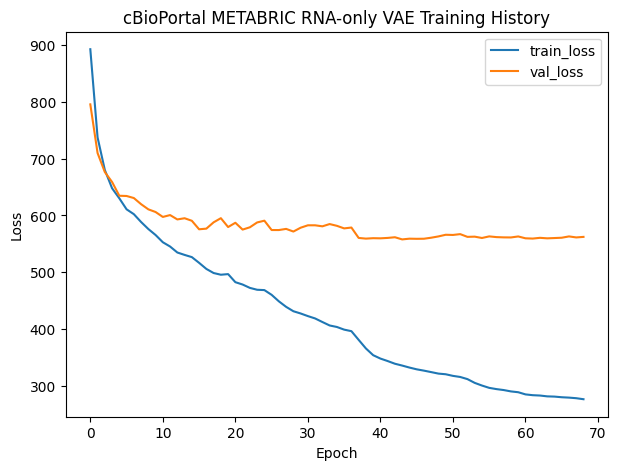

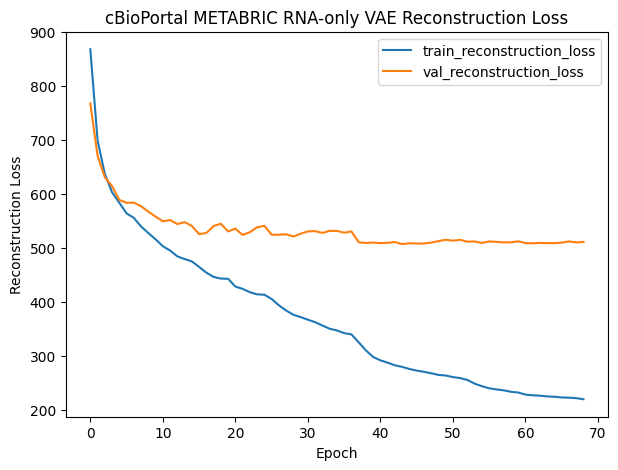

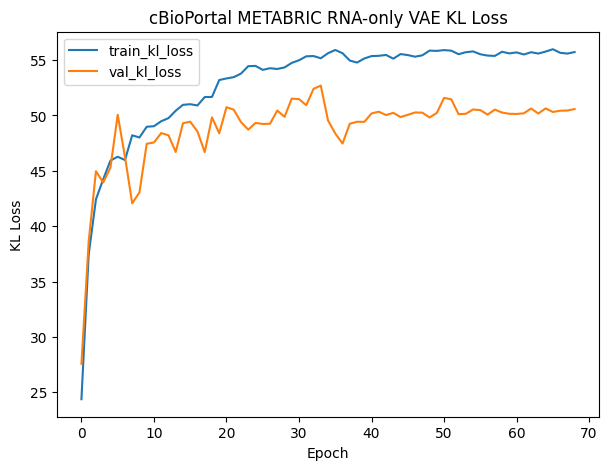

Final train loss: 275.921
Final validation loss: 562.123
Best validation loss: 557.688


{'best_epoch': 44,
 'last_epoch_run': 69,
 'monitor': 'val_loss',
 'restore_best_weights': True,
 'metrics_at_restored_epoch': {'kl_loss': 55.13072204589844,
  'loss': 335.2616882324219,
  'reconstruction_loss': 280.13104248046875,
  'val_kl_loss': 50.24024200439453,
  'val_loss': 557.687744140625,
  'val_reconstruction_loss': 507.4474792480469,
  'learning_rate': 0.0005000000237487},
 'note': 'Recorded stochastic validation metrics at restored epoch, not a fresh deterministic evaluation.'}

In [16]:
if history_df is not None:
    plot_vae_training_history(history_df, title_prefix="cBioPortal METABRIC RNA-only VAE")
    rna_training_diagnostics = summarise_metabric_encoder_history(history_df)
    thesis_display(rna_training_diagnostics)
else:
    thesis_print("RNA-only training history is not available.")


## Project Institutional Cohort into METABRIC VAE Latent Space

We apply the METABRIC-trained RNA-only VAE encoder to the institutional oligo/poly TPM cohort.

For downstream classification, we use the latent mean representation (`z_mean`) because it provides a deterministic latent vector for each sample.

In [ ]:
if RUN_RNA_ENCODER:
    ## Project Institutional Cohort ##

    latent_scores_df = project_samples_with_z_mean_encoder(
        z_mean_encoder=z_mean_encoder,
        X=X_institutional,
        sample_ids=institutional_selected_df.index,
        prefix=REPRESENTATION_NAME,
        batch_size=BATCH_SIZE,
    )

    thesis_print("Latent scores shape:")
    thesis_print(latent_scores_df.shape)

    thesis_display(latent_scores_df.head())
else:
    latent_scores_df = load_metabric_reviewed_scores(latent_scores_path, rna_completed_dir / f"{REPRESENTATION_NAME}_metadata.json", source_paths, preparation_manifest_path=source_provenance_path)


## Save Model, Projection Outputs, and Metadata

We save the fitted VAE models, scaler, selected genes, gene-overlap summary, training history, latent scores, and metadata required for reproducibility.

In [ ]:
if RUN_RNA_ENCODER:
    ## Save Outputs ##

    metadata = {
        "representation_name": REPRESENTATION_NAME,
        "model_type": "RNA-only VAE inspired by IntegrativeVAEs/CancerAI-CL",
        "external_training_dataset": "METABRIC",
        "institutional_projection_dataset": "institutional oligo/poly TPM cohort",
        "input_dim": int(input_dim),
        "latent_dim": int(LATENT_DIM),
        "n_top_variable_genes": int(N_TOP_VARIABLE_GENES),
        "n_selected_genes": int(selected_genes_df.shape[0]),
        "n_metabric_samples": int(metabric_selected_df.shape[0]),
        "n_institutional_samples": int(institutional_selected_df.shape[0]),
        "hidden_dims": list(HIDDEN_DIMS),
        "dropout_rate": float(DROPOUT_RATE),
        "learning_rate": float(LEARNING_RATE),
        "beta": float(BETA),
        "batch_size": int(BATCH_SIZE),
        "epochs_requested": int(EPOCHS),
        "epochs_trained": int(history_df.shape[0]),
        "patience": int(PATIENCE),
        "scaler_type": SCALER_TYPE,
        "validation_fraction": float(VALIDATION_FRACTION),
        "random_state": int(RANDOM_STATE),
        "training_diagnostics": summarise_metabric_encoder_history(history_df),
        "source_provenance": prepared["provenance"],
        "final_train_loss": float(history_df["loss"].iloc[-1]),
        "final_val_loss": float(history_df["val_loss"].iloc[-1]),
    }

    latent_scores_path = save_integrativevae_outputs(
        output_dir=rna_run["attempt"] / "artifacts",
        vae=vae,
        encoder=encoder,
        z_mean_encoder=z_mean_encoder,
        decoder=decoder,
        scaler=scaler,
        selected_genes_df=selected_genes_df,
        overlap_summary_df=overlap_summary_df,
        history_df=history_df,
        latent_scores_df=latent_scores_df,
        metadata=metadata,
        representation_name=REPRESENTATION_NAME,
    )

    latent_scores_path = complete_metabric_encoder_run(rna_run)

    thesis_print("Saved latent scores:")
    thesis_print(latent_scores_path)

else:
    thesis_print("Stage disabled; no output generated.")


# Downstream Evaluation of the METABRIC IntegrativeVAE Representation

The previous sections generated a breast-cancer-specific latent transcriptomic representation by training an RNA-only VAE on METABRIC and projecting the institutional oligo/poly cohort into the learned latent space.

We now evaluate whether these latent features are useful for distinguishing oligometastatic from polymetastatic patients.

The evaluation uses the same nested cross-validation logic as the main transcriptomic representation-learning notebook:

1. the latent features are used as model inputs;
2. the target is `Polymetastatic`, with 0 = oligometastatic and 1 = polymetastatic;
3. hyperparameters are selected using inner cross-validation;
4. outer-fold test metrics are used only for performance estimation;
5. model/representation selection is based on the mean inner-cross-validation macro-F1 score.

## Load Saved Latent Scores

Only cBioPortal-derived scores with matching source and preparation fingerprints are eligible.


In [19]:
metabric_integrativevae_scores_df = latent_scores_df
if metabric_integrativevae_scores_df is not None:
    thesis_display(metabric_integrativevae_scores_df.head())
else:
    thesis_print("Canonical RNA-only latent scores are not available.")


,sample_id_normalised,metabric_cbioportal_integrativevae_rna_only_latent100_latent_001,metabric_cbioportal_integrativevae_rna_only_latent100_latent_002,metabric_cbioportal_integrativevae_rna_only_latent100_latent_003,metabric_cbioportal_integrativevae_rna_only_latent100_latent_004,metabric_cbioportal_integrativevae_rna_only_latent100_latent_005,metabric_cbioportal_integrativevae_rna_only_latent100_latent_006,metabric_cbioportal_integrativevae_rna_only_latent100_latent_007,metabric_cbioportal_integrativevae_rna_only_latent100_latent_008,metabric_cbioportal_integrativevae_rna_only_latent100_latent_009,...,metabric_cbioportal_integrativevae_rna_only_latent100_latent_091,metabric_cbioportal_integrativevae_rna_only_latent100_latent_092,metabric_cbioportal_integrativevae_rna_only_latent100_latent_093,metabric_cbioportal_integrativevae_rna_only_latent100_latent_094,metabric_cbioportal_integrativevae_rna_only_latent100_latent_095,metabric_cbioportal_integrativevae_rna_only_latent100_latent_096,metabric_cbioportal_integrativevae_rna_only_latent100_latent_097,metabric_cbioportal_integrativevae_rna_only_latent100_latent_098,metabric_cbioportal_integrativevae_rna_only_latent100_latent_099,metabric_cbioportal_integrativevae_rna_only_latent100_latent_100
0,101B,-0.344,-1.935,-6.167,2.181,-1.892,8.052,0.702,-1.251,2.765,...,-6.578,0.277,1.499,0.045,-2.766,0.205,0.855,1.045,-0.828,2.163
1,108B,0.433,0.006,-3.908,-1.598,2.597,3.133,-1.336,-0.117,5.055,...,-7.928,-0.123,1.199,-0.269,-3.067,0.751,-0.074,1.768,-0.553,0.575
2,10B,-0.879,-0.903,-5.346,1.718,0.613,5.478,-0.235,-0.379,6.897,...,-5.284,1.099,0.469,0.286,-4.580,0.891,0.762,2.469,0.348,4.363
3,110B,-0.288,-0.022,-3.355,0.691,1.471,5.580,-1.816,0.207,6.693,...,-6.713,0.263,0.617,0.212,-4.531,1.473,0.509,2.473,-1.034,3.712
4,115B,0.216,-0.002,-4.043,-0.994,-0.639,5.256,-1.383,-0.961,3.291,...,-5.921,0.209,0.797,0.159,-4.168,2.124,0.118,0.681,-0.457,2.558


## Merge Latent Scores with Oligo/Poly Labels

We merge the METABRIC IntegrativeVAE latent scores with the institutional metadata containing the oligo/poly target.

This creates a modelling dataframe containing:

- sample identifiers;
- the `Polymetastatic` target;
- the 100 METABRIC IntegrativeVAE latent features.

Only latent features are used as predictors.

In [20]:
if metabric_integrativevae_scores_df is not None:
    thesis_print("RNA-only score rows:", len(metabric_integrativevae_scores_df))


RNA-only score rows: 139


## Prepare X, y, and Metadata

We separate the METABRIC IntegrativeVAE latent features from the target and sample metadata.

The input matrix `X_metabric_integrativevae` contains only the latent features. The target `y_metabric_integrativevae` contains the binary oligo/poly label.

In [ ]:
X_metabric_integrativevae = None
if metabric_integrativevae_scores_df is not None:
    X_metabric_integrativevae, y_metabric_integrativevae, metadata_metabric_integrativevae_df = align_metabric_latent_scores(
        metabric_integrativevae_scores_df, metadata_df, REPRESENTATION_NAME)


## Define Nested Cross-Validation Setup

We use stratified nested cross-validation to evaluate the METABRIC IntegrativeVAE representation.

The inner loop is used for hyperparameter selection. The outer loop is used only to estimate out-of-training performance.

The scoring metric is macro-F1, matching the current modelling strategy used across clinical, mutation, and transcriptomic representation analyses.

In [22]:
thesis_print("Frozen outer folds:", len(outer_splits))
thesis_print("Inner CV:", inner_cv)
thesis_print("Selection metric:", scoring)


Frozen outer folds: 5
Inner CV: StratifiedKFold(n_splits=5, random_state=42, shuffle=True)
Selection metric: f1_macro


## Established Classifier Families

Both fixed latent representations use L1 logistic regression, Random Forest and XGBoost, with the existing TPM classifier grids and optional SMOTE choices. These 100/128-dimensional representations use no additional SelectKBest step. Institutional standardisation, resampling and classifier fitting occur within each CV training pipeline.


In [23]:
thesis_print("Families: logreg_l1, random_forest, xgboost; established grids are built by the thesis-local evaluator.")


Families: logreg_l1, random_forest, xgboost; established grids are built by the thesis-local evaluator.


## Run Nested Cross-Validation

We evaluate the METABRIC IntegrativeVAE representation using nested cross-validation.

The reported outer-fold test metrics estimate out-of-training performance. They are not used to select the representation.

The key model-selection quantity is the mean inner-cross-validation macro-F1 score.

In [ ]:
rna_results, rna_predictions = {}, {}
if X_metabric_integrativevae is not None:
    rna_results, rna_predictions = evaluate_metabric_latent_representation(
        X_metabric_integrativevae, y_metabric_integrativevae, REPRESENTATION_NAME,
        metadata_metabric_integrativevae_df, metadata_df, y, outer_splits, inner_cv,
        output_dir, metabric_registry, latent_scores_path, run_nested_cv=RUN_NESTED_CV, random_state=RANDOM_STATE)
elif RUN_NESTED_CV:
    raise FileNotFoundError("Canonical RNA-only latent scores are required before nested CV.")


## Summarise METABRIC IntegrativeVAE Performance

We aggregate the nested cross-validation results across outer folds.

The summary reports the mean inner-cross-validation macro-F1 score, together with outer-fold test metrics such as ROC-AUC, balanced accuracy, F1, sensitivity, specificity, and train performance.

The mean inner-cross-validation score is used for model/representation selection; outer-fold test metrics are performance estimates.

In [25]:
if rna_results:
    thesis_display(summarise_representation_results(pd.concat(rna_results.values(), ignore_index=True)))
else:
    thesis_print("Canonical RNA-only performance estimates are not available.")


,mean_inner_cv_score,std_inner_cv_score,mean_test_roc_auc,mean_test_balanced_accuracy,mean_train_roc_auc,train_test_gap
representation,,,,,,
metabric_cbioportal_integrativevae_rna_only_latent100_random_forest,0.545,0.065,0.432,0.501,0.977,0.545
metabric_cbioportal_integrativevae_rna_only_latent100_xgboost,0.520,0.053,0.498,0.493,0.892,0.394
metabric_cbioportal_integrativevae_rna_only_latent100_logreg_l1,0.498,0.058,0.539,0.584,0.734,0.195


## Save Downstream Evaluation Outputs

We save the fold-level nested-CV results, prediction table, and summary table for the METABRIC IntegrativeVAE representation.

These files can later be compared with the results from Tybalt, MultiPLIER, GenomicSuperSignature, PCA, and the gene-level baseline.

In [ ]:
thesis_print("The evaluator saves per-family fold results, OOF predictions and outer-fold latent rankings.")


## METABRIC RNA-only Representation

The RNA-only VAE uses 1,000 genes selected by variance in the METABRIC training partition from the 16,950-gene harmonised space. Its frozen latent-mean encoder produces 100 features for each institutional patient.


## Interpretation of Downstream Evaluation

The RNA-only representation is evaluated with L1 logistic regression, Random Forest and XGBoost. Model selection uses mean inner-CV macro-F1; held-out outer-fold and pooled OOF metrics describe predictive performance. Training–test differences and cross-platform measurement differences inform the limitations of transfer.


# Original IntegrativeVAEs HVAE RNA-Branch Adaptation

The previous section implemented an RNA-only VAE inspired by the IntegrativeVAEs/CancerAI-CL framework.

In this section, we implement a more faithful RNA-only adaptation of the original IntegrativeVAEs HVAE code. In the original repository, RNA expression is handled as the numerical modality through the `numVAE` / `build_s2()` branch of the `HVAE` class.

The original RNA branch uses:

1. a dense encoder layer of size `ds`;
2. batch normalisation;
3. latent mean and log-variance layers of size `ds // 2`;
4. stochastic sampling using the VAE reparameterisation trick;
5. a dense decoder layer of size `ds`;
6. batch normalisation and dropout;
7. a linear reconstruction output;
8. mean-squared-error reconstruction loss plus KL or MMD regularisation.

Here, we reproduce this RNA branch in a TensorFlow/Keras-compatible way and apply it to the same METABRIC/institutional harmonised expression matrices used above.

## Prepare METABRIC and Institutional Matrices for the HVAE RNA Branch

The original IntegrativeVAEs code applies min-max normalisation to the RNA-expression matrix before training the RNA numerical VAE branch.

Here, we apply min-max scaling using METABRIC as the external training dataset. The same METABRIC-derived scaling parameters are then applied to the institutional samples.

The fixed transformation avoids fitting on the institutional oligo/poly cohort. It does not make microarray and RNA-seq measurements equivalent.

In [27]:
## Scale METABRIC and Institutional Expression for HVAE RNA Branch ##

HVAE_DS = 256
HVAE_LATENT_DIM = HVAE_DS // 2
HVAE_ACTIVATION = "elu"
HVAE_DROPOUT_RATE = 0.2
HVAE_BETA = 1.0
HVAE_LEARNING_RATE = 1e-3
HVAE_EPOCHS = 150
HVAE_BATCH_SIZE = 64
HVAE_VALIDATION_FRACTION = 0.2

HVAE_REPRESENTATION_NAME = (
    f"metabric_cbioportal_integrativevae_hvae_rna_ds{HVAE_DS}_latent{HVAE_LATENT_DIM}"
)

thesis_print("Representation name:")
thesis_print(HVAE_REPRESENTATION_NAME)


hvae_completed_dir = hvae_output_dir / f"{HVAE_REPRESENTATION_NAME}_completed"
hvae_latent_scores_path = hvae_completed_dir / f"transcriptomics_{HVAE_REPRESENTATION_NAME}_scores.csv"
hvae_history_path = hvae_completed_dir / f"{HVAE_REPRESENTATION_NAME}_training_history.csv"

if prepared is not None:
    # Use the same harmonised matrices generated earlier.
    # metabric_selected_df and institutional_selected_df should have identical columns.

    assert list(metabric_selected_df.columns) == list(institutional_selected_df.columns)

    X_metabric_hvae_raw = metabric_selected_df.astype(float).copy()
    X_institutional_hvae_raw = institutional_selected_df.astype(float).copy()

    X_metabric_train_raw, X_metabric_val_raw = train_test_split(
        X_metabric_hvae_raw,
        test_size=HVAE_VALIDATION_FRACTION,
        random_state=RANDOM_STATE,
        shuffle=True,
    )

    metabric_min = X_metabric_train_raw.min(axis=0)
    metabric_max = X_metabric_train_raw.max(axis=0)
    metabric_range = metabric_max - metabric_min

    # Avoid division by zero for constant genes.
    metabric_range = metabric_range.replace(0, 1.0)

    X_metabric_train_hvae = (
        (X_metabric_train_raw - metabric_min) / metabric_range
    ).astype(np.float32)

    X_metabric_val_hvae = (
        (X_metabric_val_raw - metabric_min) / metabric_range
    ).astype(np.float32)

    X_metabric_full_hvae = (
        (X_metabric_hvae_raw - metabric_min) / metabric_range
    ).astype(np.float32)

    X_institutional_hvae = (
        (X_institutional_hvae_raw - metabric_min) / metabric_range
    ).astype(np.float32)

    thesis_print("METABRIC train shape:")
    thesis_print(X_metabric_train_hvae.shape)

    thesis_print("\nMETABRIC validation shape:")
    thesis_print(X_metabric_val_hvae.shape)

    thesis_print("\nInstitutional shape:")
    thesis_print(X_institutional_hvae.shape)

    thesis_print("\nNumber of shared genes:")
    thesis_print(X_metabric_train_hvae.shape[1])


Representation name:
metabric_cbioportal_integrativevae_hvae_rna_ds256_latent128
METABRIC train shape:
(1584, 1000)

METABRIC validation shape:
(396, 1000)

Institutional shape:
(139, 1000)

Number of model-facing genes:
1000


## Train Original HVAE RNA-Branch Adaptation on METABRIC

We train the adapted original HVAE RNA branch on the METABRIC gene-expression matrix.

The architecture follows the original `build_s2()` numerical branch from the IntegrativeVAEs implementation. With `ds = 256`, the RNA latent representation has dimension `ds // 2 = 128`.

The model is trained only on METABRIC. The institutional cohort is not used to train or tune the VAE.

In [ ]:
if RUN_HVAE_ENCODER:
    ## Train Original HVAE RNA-Branch Adaptation ##

    hvae_run = begin_metabric_encoder_run(hvae_output_dir, HVAE_REPRESENTATION_NAME, prepared["provenance"])
    input_dim = X_metabric_train_hvae.shape[1]

    hvae_rna_vae, hvae_rna_encoder, hvae_rna_z_mean_encoder, hvae_rna_decoder = (
        build_integrativevae_hvae_rna_branch(
            input_dim=input_dim,
            ds=HVAE_DS,
            activation=HVAE_ACTIVATION,
            dropout_rate=HVAE_DROPOUT_RATE,
            beta=HVAE_BETA,
            learning_rate=HVAE_LEARNING_RATE,
        )
    )

    hvae_rna_vae.summary()

    hvae_early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", mode="min", patience=PATIENCE, min_delta=0, restore_best_weights=True)
    hvae_history = hvae_rna_vae.fit(
        X_metabric_train_hvae,
        epochs=HVAE_EPOCHS,
        batch_size=HVAE_BATCH_SIZE,
        shuffle=True,
        validation_data=(X_metabric_val_hvae, None),
        callbacks=[hvae_early_stopping] + metabric_encoder_operational_callbacks(hvae_run),
        verbose=1,
    )

    hvae_history_df = pd.DataFrame(hvae_history.history)

    thesis_display(hvae_history_df.tail())

else:
    hvae_history_df = pd.read_csv(hvae_history_path) if hvae_history_path.exists() else None


## Plot HVAE RNA-Branch Training History

We inspect the METABRIC training and validation losses to check whether the adapted HVAE RNA branch converged and whether there is evidence of overfitting.

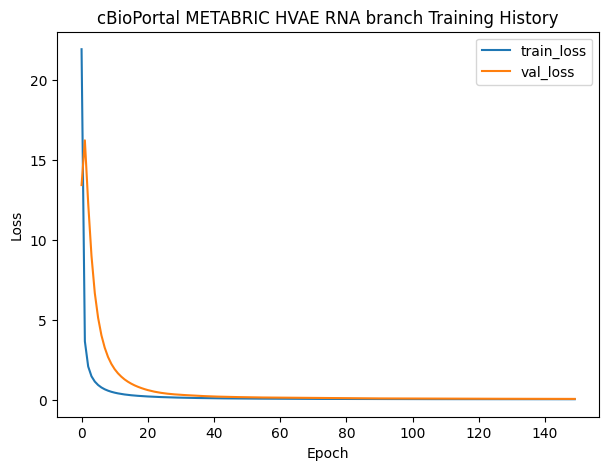

Final train loss: 0.039
Final validation loss: 0.059
Best validation loss: 0.059


{'best_epoch': 150,
 'last_epoch_run': 150,
 'monitor': 'val_loss',
 'restore_best_weights': True,
 'metrics_at_restored_epoch': {'loss': 0.039,
  'val_loss': 0.059},
 'note': 'Recorded stochastic validation metrics at restored epoch, not a fresh deterministic evaluation.'}

In [29]:
if hvae_history_df is not None:
    plot_vae_training_history(hvae_history_df, title_prefix="cBioPortal METABRIC HVAE RNA branch")
    thesis_display(summarise_metabric_encoder_history(hvae_history_df))
else:
    thesis_print("HVAE training history is not available.")


## Project Institutional Samples into the HVAE RNA Latent Space

After training the HVAE RNA branch on METABRIC, we apply the deterministic `z_mean` encoder to the institutional oligo/poly samples.

The resulting features represent the institutional samples in the latent space learned from METABRIC breast cancer RNA expression.

In [ ]:
if RUN_HVAE_ENCODER:
    ## Project Institutional Samples with HVAE RNA z_mean Encoder ##

    hvae_institutional_latent = hvae_rna_z_mean_encoder.predict(
        X_institutional_hvae,
        batch_size=HVAE_BATCH_SIZE,
    )

    hvae_latent_feature_names = [
        f"{HVAE_REPRESENTATION_NAME}_latent_{idx + 1}"
        for idx in range(hvae_institutional_latent.shape[1])
    ]

    hvae_latent_scores_df = pd.DataFrame(
        hvae_institutional_latent,
        index=institutional_selected_df.index,
        columns=hvae_latent_feature_names,
    )

    hvae_latent_scores_df = (
        hvae_latent_scores_df
        .reset_index()
        .rename(columns={"index": "sample_id_normalised"})
    )

    thesis_print("HVAE institutional latent scores shape:")
    thesis_print(hvae_latent_scores_df.shape)

    thesis_display(hvae_latent_scores_df.head())
else:
    hvae_latent_scores_df = load_metabric_reviewed_scores(hvae_latent_scores_path, hvae_completed_dir / f"{HVAE_REPRESENTATION_NAME}_metadata.json", source_paths, preparation_manifest_path=source_provenance_path)


## Save HVAE RNA-Branch Representation Outputs

We save the latent scores generated using the original IntegrativeVAEs HVAE RNA-branch adaptation.

The main output is the latent-score CSV file, which can be used for downstream oligo/poly nested cross-validation in the same way as the other transcriptomic representations.

In [ ]:
if RUN_HVAE_ENCODER:
    ## Save HVAE RNA-Branch Representation Outputs ##

    hvae_artifact_dir = hvae_run["attempt"] / "artifacts"

    hvae_artifact_dir.mkdir(parents=True, exist_ok=True)

    hvae_latent_scores_path = (
        hvae_artifact_dir
        / f"transcriptomics_{HVAE_REPRESENTATION_NAME}_scores.csv"
    )

    hvae_history_path = (
        hvae_artifact_dir
        / f"{HVAE_REPRESENTATION_NAME}_training_history.csv"
    )

    hvae_selected_genes_path = (
        hvae_artifact_dir
        / f"{HVAE_REPRESENTATION_NAME}_selected_genes.csv"
    )

    hvae_scaling_params_path = (
        hvae_artifact_dir
        / f"{HVAE_REPRESENTATION_NAME}_metabric_minmax_scaling_params.csv"
    )

    hvae_latent_scores_df.to_csv(
        hvae_latent_scores_path,
        index=False,
    )

    hvae_history_df.to_csv(
        hvae_history_path,
        index=False,
    )

    selected_genes_df.to_csv(
        hvae_selected_genes_path,
        index=False,
    )

    hvae_scaling_params_df = pd.DataFrame({
        "gene": metabric_min.index,
        "metabric_train_min": metabric_min.values,
        "metabric_train_max": metabric_max.values,
        "metabric_train_range": metabric_range.values,
    })

    hvae_scaling_params_df.to_csv(
        hvae_scaling_params_path,
        index=False,
    )

    hvae_rna_z_mean_encoder.save(
        hvae_artifact_dir
        / f"{HVAE_REPRESENTATION_NAME}_z_mean_encoder.keras"
    )

    thesis_print("Saved HVAE latent scores:")
    thesis_print(hvae_latent_scores_path)

    thesis_print("\nSaved HVAE training history:")
    thesis_print(hvae_history_path)

    thesis_print("\nSaved HVAE z_mean encoder:")
    thesis_print(
        hvae_artifact_dir
        / f"{HVAE_REPRESENTATION_NAME}_z_mean_encoder.keras"
    )
    (hvae_artifact_dir / f"{HVAE_REPRESENTATION_NAME}_metadata.json").write_text(json.dumps({"training_diagnostics": summarise_metabric_encoder_history(hvae_history_df), "source_provenance": prepared["provenance"]}, indent=2))

    hvae_latent_scores_path = complete_metabric_encoder_run(hvae_run)

else:
    thesis_print("Stage disabled; no output generated.")


# Downstream Evaluation of the Original HVAE RNA-Branch Representation

We now evaluate whether the latent features generated using the original IntegrativeVAEs HVAE RNA-branch adaptation are useful for the institutional oligo/poly classification task.

As before, the VAE itself was trained only on METABRIC. The institutional cohort is used only for downstream supervised evaluation with nested cross-validation.

In [32]:
hvae_scores_df = hvae_latent_scores_df
if hvae_scores_df is not None:
    thesis_display(hvae_scores_df.head())


,sample_id_normalised,metabric_cbioportal_integrativevae_hvae_rna_ds256_latent128_latent_1,metabric_cbioportal_integrativevae_hvae_rna_ds256_latent128_latent_2,metabric_cbioportal_integrativevae_hvae_rna_ds256_latent128_latent_3,metabric_cbioportal_integrativevae_hvae_rna_ds256_latent128_latent_4,metabric_cbioportal_integrativevae_hvae_rna_ds256_latent128_latent_5,metabric_cbioportal_integrativevae_hvae_rna_ds256_latent128_latent_6,metabric_cbioportal_integrativevae_hvae_rna_ds256_latent128_latent_7,metabric_cbioportal_integrativevae_hvae_rna_ds256_latent128_latent_8,metabric_cbioportal_integrativevae_hvae_rna_ds256_latent128_latent_9,...,metabric_cbioportal_integrativevae_hvae_rna_ds256_latent128_latent_119,metabric_cbioportal_integrativevae_hvae_rna_ds256_latent128_latent_120,metabric_cbioportal_integrativevae_hvae_rna_ds256_latent128_latent_121,metabric_cbioportal_integrativevae_hvae_rna_ds256_latent128_latent_122,metabric_cbioportal_integrativevae_hvae_rna_ds256_latent128_latent_123,metabric_cbioportal_integrativevae_hvae_rna_ds256_latent128_latent_124,metabric_cbioportal_integrativevae_hvae_rna_ds256_latent128_latent_125,metabric_cbioportal_integrativevae_hvae_rna_ds256_latent128_latent_126,metabric_cbioportal_integrativevae_hvae_rna_ds256_latent128_latent_127,metabric_cbioportal_integrativevae_hvae_rna_ds256_latent128_latent_128
0,101B,-10.282,0.889,20.132,24.287,13.949,-14.784,11.097,-17.292,46.216,...,23.287,-2.832,8.773,-9.631,12.991,-12.091,35.937,9.700,-25.741,-6.998
1,108B,0.323,-2.730,23.365,19.266,14.117,-16.909,10.476,-7.355,41.854,...,23.448,-2.787,11.639,-4.840,1.598,-20.249,15.400,13.385,-16.316,2.038
2,10B,-8.874,-0.726,24.818,13.247,13.279,-16.795,2.486,-18.298,34.308,...,21.087,-0.164,8.391,-3.472,9.163,-7.781,32.321,10.072,-15.564,-1.255
3,110B,0.581,2.822,23.838,6.573,14.297,-15.645,-1.984,-13.720,44.858,...,23.074,-1.712,6.852,-0.907,10.168,-13.061,21.467,9.041,-17.459,-1.782
4,115B,-5.147,-2.634,14.928,12.956,12.502,-13.086,-0.336,-11.206,22.937,...,20.489,-1.868,11.508,0.020,3.988,-10.113,14.747,11.878,-10.677,3.252


## Merge HVAE Latent Scores with Oligo/Poly Labels

The HVAE latent scores are merged with the institutional oligo/poly labels using the sample identifier.

In [33]:
if hvae_scores_df is not None:
    thesis_print("HVAE score rows:", len(hvae_scores_df))


HVAE score rows: 139


## Prepare HVAE X, y, and Metadata

We separate the HVAE latent features from the oligo/poly target and sample metadata.

In [ ]:
X_hvae = None
if hvae_scores_df is not None:
    X_hvae, y_hvae, metadata_hvae_df = align_metabric_latent_scores(hvae_scores_df, metadata_df, HVAE_REPRESENTATION_NAME)


## Run Nested Cross-Validation for the HVAE RNA-Branch Representation

We evaluate the HVAE RNA-branch representation using the same nested cross-validation setup and macro-F1 scoring strategy used for the previous representation.

The inner loop is used for hyperparameter selection, while outer-fold metrics are used only as out-of-training performance estimates.

In [ ]:
hvae_results, hvae_predictions = {}, {}
if X_hvae is not None:
    hvae_results, hvae_predictions = evaluate_metabric_latent_representation(
        X_hvae, y_hvae, HVAE_REPRESENTATION_NAME, metadata_hvae_df, metadata_df, y,
        outer_splits, inner_cv, output_dir, metabric_registry, hvae_latent_scores_path,
        run_nested_cv=RUN_NESTED_CV, random_state=RANDOM_STATE)
elif RUN_NESTED_CV:
    raise FileNotFoundError("Canonical HVAE latent scores are required before nested CV.")


## Summarise HVAE RNA-Branch Downstream Performance

We aggregate the nested cross-validation results across outer folds.

The mean inner-cross-validation macro-F1 score is the primary quantity for representation/model selection. Outer-fold test metrics are interpreted as performance estimates.

In [36]:
if hvae_results:
    thesis_display(summarise_representation_results(pd.concat(hvae_results.values(), ignore_index=True)))
else:
    thesis_print("Canonical HVAE performance estimates are not available.")


,mean_inner_cv_score,std_inner_cv_score,mean_test_roc_auc,mean_test_balanced_accuracy,mean_train_roc_auc,train_test_gap
representation,,,,,,
metabric_cbioportal_integrativevae_hvae_rna_ds256_latent128_logreg_l1,0.562,0.034,0.557,0.533,0.920,0.363
metabric_cbioportal_integrativevae_hvae_rna_ds256_latent128_xgboost,0.547,0.044,0.494,0.474,0.860,0.366
metabric_cbioportal_integrativevae_hvae_rna_ds256_latent128_random_forest,0.518,0.060,0.487,0.457,0.974,0.487


## Save HVAE Downstream Evaluation Outputs

We save the fold-level nested-CV results and prediction table for the original HVAE RNA-branch representation.

These outputs document the downstream supervised evaluation of the METABRIC-trained HVAE RNA latent features and allow comparison with the previous RNA-only VAE implementation and with other transcriptomic representations.

In [ ]:
thesis_print("The evaluator saves canonical per-family outputs separately.")


## HVAE RNA-Branch Representation

The HVAE RNA branch produces 128 latent-mean features from the same 1,000 selected genes, using its frozen METABRIC-training min–max transformation. Its downstream classifiers follow the same five-outer/five-inner-fold protocol. Full-cohort models and gene-level attribution serve interpretation only.


## Compare the METABRIC Representations

The final benchmark contains two external representations × three classifier families. The comparison uses complete results from the full cBioPortal source. Combinations are ranked and selected only by mean inner-CV macro-F1; outer-test metrics and fold-win counts are diagnostic only. Pooled metrics concatenate the held-out predictions; mean ± SD summarises the five fold-specific metrics. These can differ numerically.




,mean_inner_cv_score,std_inner_cv_score,mean_test_roc_auc,mean_test_balanced_accuracy,mean_train_roc_auc,train_test_gap
representation,,,,,,
metabric_cbioportal_integrativevae_hvae_rna_ds256_latent128_logreg_l1,0.562,0.034,0.557,0.533,0.920,0.363
metabric_cbioportal_integrativevae_hvae_rna_ds256_latent128_xgboost,0.547,0.044,0.494,0.474,0.860,0.366
metabric_cbioportal_integrativevae_rna_only_latent100_random_forest,0.545,0.065,0.432,0.501,0.977,0.545
metabric_cbioportal_integrativevae_rna_only_latent100_xgboost,0.520,0.053,0.498,0.493,0.892,0.394
metabric_cbioportal_integrativevae_hvae_rna_ds256_latent128_random_forest,0.518,0.060,0.487,0.457,0.974,0.487
metabric_cbioportal_integrativevae_rna_only_latent100_logreg_l1,0.498,0.058,0.539,0.584,0.734,0.195


,roc_auc,balanced_accuracy,f1_macro,precision,recall,specificity,average_precision,brier_score
representation,,,,,,,,
metabric_cbioportal_integrativevae_rna_only_latent100_logreg_l1,0.524,0.587,0.581,0.689,0.600,0.574,0.616,0.277
metabric_cbioportal_integrativevae_rna_only_latent100_random_forest,0.448,0.504,0.496,0.614,0.729,0.278,0.553,0.254
metabric_cbioportal_integrativevae_rna_only_latent100_xgboost,0.509,0.496,0.495,0.609,0.659,0.333,0.605,0.248
metabric_cbioportal_integrativevae_hvae_rna_ds256_latent128_logreg_l1,0.565,0.534,0.534,0.639,0.624,0.444,0.688,0.281
metabric_cbioportal_integrativevae_hvae_rna_ds256_latent128_random_forest,0.483,0.457,0.453,0.581,0.635,0.278,0.650,0.248
metabric_cbioportal_integrativevae_hvae_rna_ds256_latent128_xgboost,0.453,0.473,0.473,0.590,0.576,0.370,0.590,0.251


train_roc_auc            \
                                                            mean       std   
representation                                                               
metabric_cbioportal_integrativevae_hvae_rna_ds2...      0.920  0.006   
metabric_cbioportal_integrativevae_hvae_rna_ds2...      0.974  0.016   
metabric_cbioportal_integrativevae_hvae_rna_ds2...      0.860  0.069   
metabric_cbioportal_integrativevae_rna_only_lat...      0.734  0.113   
metabric_cbioportal_integrativevae_rna_only_lat...      0.977  0.011   
metabric_cbioportal_integrativevae_rna_only_lat...      0.892  0.066   

                                                   train_balanced_accuracy  \
                                                                      mean   
representation                                                               
metabric_cbioportal_integrativevae_hvae_rna_ds2...                0.830   
metabric_cbioportal_integrativevae_hvae_rna_ds2...                0.900   
metabric_cbioportal_integrativevae_hvae_rna_ds2...                0.772   
metabric_cbioportal_integrativevae_rna_only_lat...                0.665   
metabric_cbioportal_integrativevae_rna_only_lat...                0.891   
metabric_cbioportal_integrativevae_rna_only_lat...                0.782   

                                                             train_f1_macro  \
                                                         std           mean   
representation                                                                
metabric_cbioportal_integrativevae_hvae_rna_ds2...  0.022       0.830   
metabric_cbioportal_integrativevae_hvae_rna_ds2...  0.044       0.903   
metabric_cbioportal_integrativevae_hvae_rna_ds2...  0.083       0.764   
metabric_cbioportal_integrativevae_rna_only_lat...  0.095       0.661   
metabric_cbioportal_integrativevae_rna_only_lat...  0.037       0.904   
metabric_cbioportal_integrativevae_rna_only_lat...  0.057       0.780   

                                                             train_precision  \
                                                         std            mean   
representation                                                                 
metabric_cbioportal_integrativevae_hvae_rna_ds2...  0.017        0.866   
metabric_cbioportal_integrativevae_hvae_rna_ds2...  0.048        0.917   
metabric_cbioportal_integrativevae_hvae_rna_ds2...  0.075        0.845   
metabric_cbioportal_integrativevae_rna_only_lat...  0.103        0.739   
metabric_cbioportal_integrativevae_rna_only_lat...  0.036        0.884   
metabric_cbioportal_integrativevae_rna_only_lat...  0.064        0.833   

                                                             train_recall  \
                                                         std         mean   
representation                                                              
metabric_cbioportal_integrativevae_hvae_rna_ds2...  0.037     0.876   
metabric_cbioportal_integrativevae_hvae_rna_ds2...  0.035     0.935   
metabric_cbioportal_integrativevae_hvae_rna_ds2...  0.093     0.779   
metabric_cbioportal_integrativevae_rna_only_lat...  0.071     0.709   
metabric_cbioportal_integrativevae_rna_only_lat...  0.031     0.985   
metabric_cbioportal_integrativevae_rna_only_lat...  0.042     0.826   

                                                              ...  \
                                                         std  ...   
representation                                                ...   
metabric_cbioportal_integrativevae_hvae_rna_ds2...  0.042  ...   
metabric_cbioportal_integrativevae_hvae_rna_ds2...  0.061  ...   
metabric_cbioportal_integrativevae_hvae_rna_ds2...  0.031  ...   
metabric_cbioportal_integrativevae_rna_only_lat...  0.176  ...   
metabric_cbioportal_integrativevae_rna_only_lat...  0.021  ...   
metabric_cbioportal_integrativevae_rna_only_lat...  0.129  ...   

                                                   test_precision           

,outer_fold,representation,best_inner_score,rank,is_winner
0,1,metabric_cbioportal_integrativevae_hvae_rna_ds...,0.586,1,True
1,1,metabric_cbioportal_integrativevae_hvae_rna_ds...,0.552,2,False
2,1,metabric_cbioportal_integrativevae_hvae_rna_ds...,0.486,3,False
3,1,metabric_cbioportal_integrativevae_rna_only_la...,0.473,4,False
4,1,metabric_cbioportal_integrativevae_rna_only_la...,0.445,5,False
5,1,metabric_cbioportal_integrativevae_rna_only_la...,0.433,6,False
6,2,metabric_cbioportal_integrativevae_rna_only_la...,0.534,1,True
7,2,metabric_cbioportal_integrativevae_rna_only_la...,0.517,2,False
8,2,metabric_cbioportal_integrativevae_hvae_rna_ds...,0.517,3,False
9,2,metabric_cbioportal_integrativevae_rna_only_la...,0.497,4,False


,outer_fold_wins
representation,
metabric_cbioportal_integrativevae_rna_only_latent100_logreg_l1,0
metabric_cbioportal_integrativevae_rna_only_latent100_random_forest,2
metabric_cbioportal_integrativevae_rna_only_latent100_xgboost,0
metabric_cbioportal_integrativevae_hvae_rna_ds256_latent128_logreg_l1,3
metabric_cbioportal_integrativevae_hvae_rna_ds256_latent128_random_forest,0
metabric_cbioportal_integrativevae_hvae_rna_ds256_latent128_xgboost,0


Selected by mean inner-CV macro-F1: metabric_cbioportal_integrativevae_hvae_rna_ds256_latent128_logreg_l1


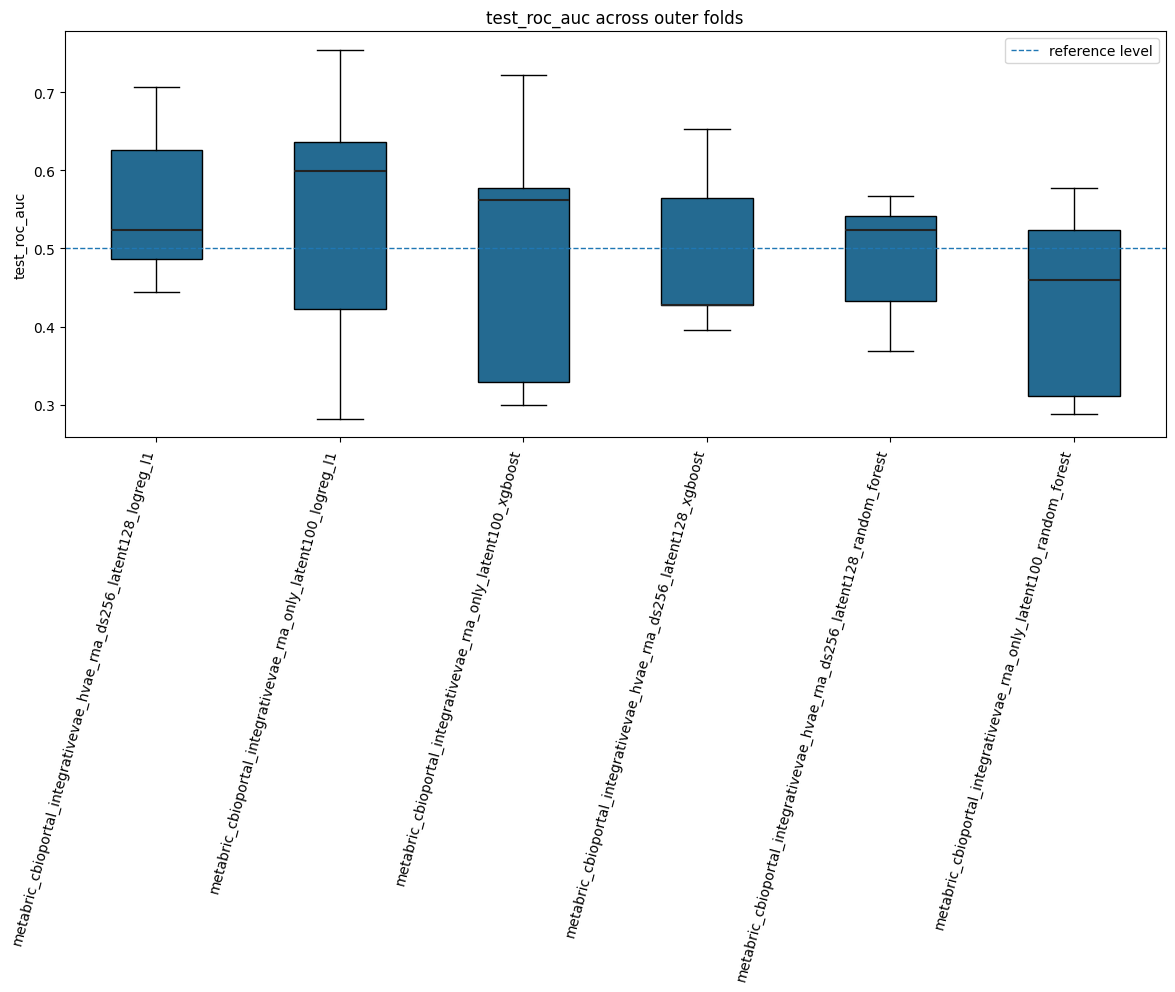

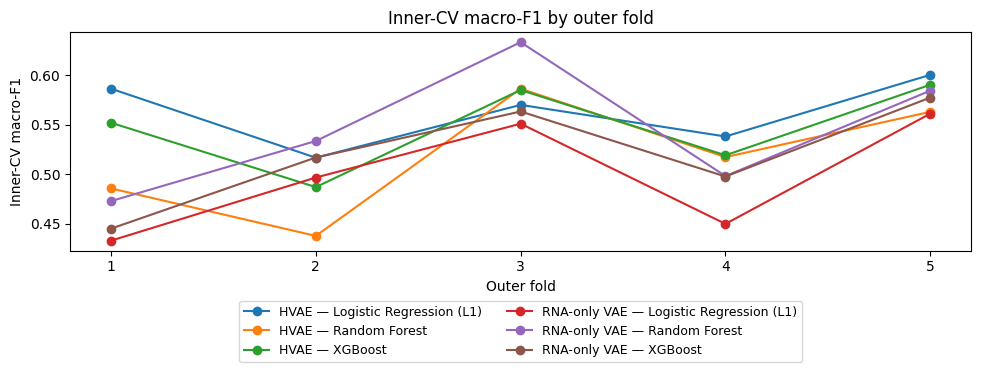

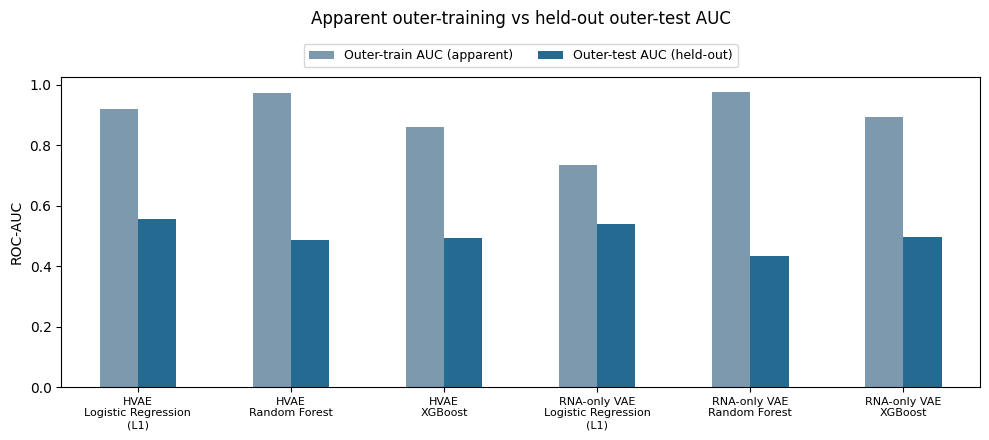

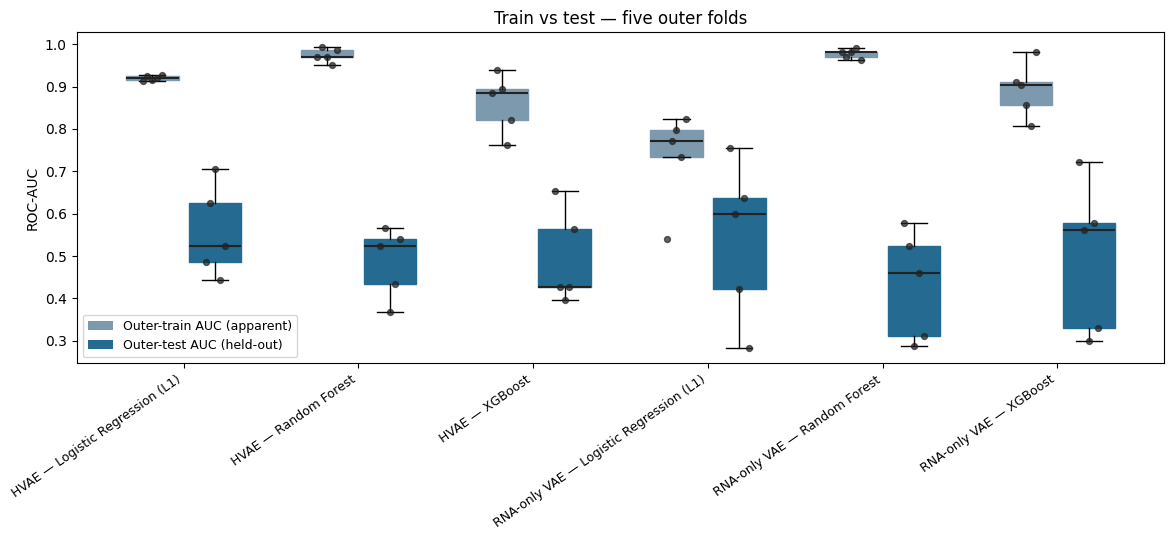

Grouped bars show the preserved mean AUC across outer folds. The additional boxplots retain all five fold values per series, shown as dots. Outer-train AUC is resubstitution (apparent) performance on patients used to fit each outer-fold model; outer-test AUC is held-out performance. Their separation is an overfitting diagnostic.

In [38]:
all_results = {**rna_results, **hvae_results}
all_predictions = {**rna_predictions, **hvae_predictions}
selected_combination = None
if len(all_results) == 6 and set(all_results) == set(metabric_registry):
    all_metabric_representation_results_df = pd.concat(all_results.values(), ignore_index=True)
    inner_rankings_df, inner_wins_df = rank_tpm_inner_scores(all_metabric_representation_results_df, list(metabric_registry))
    validated_oof = {name: validate_tpm_oof(all_predictions[name], name, metadata_df, y, outer_splits) for name in all_results}
    pooled_oof_df = pd.DataFrame([{"representation": name, **tpm_pooled_oof_metrics(frame)} for name, frame in validated_oof.items()]).set_index("representation")
    summary_df = summarise_representation_results(all_metabric_representation_results_df)
    selected_combination = select_mean_inner_combination(summary_df)
    fold_metric_cols = [c for c in all_metabric_representation_results_df if c.startswith(("train_", "test_"))]
    fold_summary_df = all_metabric_representation_results_df.groupby("representation")[fold_metric_cols].agg(["mean", "std"])
    for stem, frame, use_index in [
        ("all_nested_cv_results", all_metabric_representation_results_df, False),
        ("all_oof_predictions", pd.concat(validated_oof.values(), ignore_index=True), False),
        ("model_selection_summary", summary_df, True), ("fold_metrics_mean_sd", fold_summary_df, True),
        ("pooled_oof_metrics", pooled_oof_df, True), ("inner_fold_rankings", inner_rankings_df, False),
        ("inner_fold_win_counts", inner_wins_df, True)]:
        frame.to_csv(output_dir / f"metabric_cbioportal_{stem}_reviewed.csv", index=use_index)
    thesis_display(summary_df, pooled_oof_df, fold_summary_df, inner_rankings_df, inner_wins_df)
    thesis_print("Selected by mean inner-CV macro-F1:", selected_combination)
    plot_metric_boxplots(all_metabric_representation_results_df, metric="test_roc_auc", top_n=6, chance_level=0.5)
    plot_latent_outer_scores(all_metabric_representation_results_df.pivot(index="outer_fold", columns="representation", values="best_inner_score"))
    plt.show()
    # Preserve the existing summary artifact for provenance; its gap column is not plotted.
    train_test_means = all_metabric_representation_results_df.groupby("representation")[["train_roc_auc", "test_roc_auc"]].mean()
    train_test_means["train_test_gap"] = train_test_means.train_roc_auc - train_test_means.test_roc_auc
    train_test_means.to_csv(output_dir / "metabric_cbioportal_train_test_comparison_reviewed.csv")
    plot_latent_train_test(train_test_means)
    plt.show()
    plot_latent_train_test_folds(all_metabric_representation_results_df)
    plt.tight_layout(); plt.show()
else:
    thesis_print("Complete canonical results for all six combinations are required for global selection.")
display(Markdown('Grouped bars show the preserved mean AUC across outer folds. The additional boxplots retain all five fold values per series, shown as dots. Outer-train AUC is resubstitution (apparent) performance on patients used to fit each outer-fold model; outer-test AUC is held-out performance. Their separation is an overfitting diagnostic.'))


## Interpretation of model selection

HVAE latent128 with L1 logistic regression achieved the highest mean inner-CV macro-F1 across the six manual combinations (0.562374 ± 0.034481) and was therefore selected. Neither outer-test metrics nor fold-win counts determined this choice. Mean outer-fold ROC-AUC was 0.557112, indicating only modest discrimination above chance. The representation may retain some predictive signal, but these results do not establish that the signal is strong or reproducible.

Pooled sensitivity for polymetastatic patients (0.623529) exceeded specificity for oligometastatic patients (0.444444). At the evaluated threshold, the model recognised polymetastatic cases more often. This imbalance and the modest performance do not support clinical usefulness.


## Encoder Training and Validation

| Component | RNA-only VAE | HVAE RNA branch |
|---|---|---|
| Encoder training | METABRIC training partition only | METABRIC training partition only |
| Institutional X or oligo/poly labels during training | Neither | Neither |
| Gene ranking | METABRIC training variance among harmonised shared genes | Same fixed selected genes |
| Missing external values | METABRIC training medians | Same external training medians |
| Scaling | StandardScaler fitted on METABRIC training rows | Min/max fitted on METABRIC training rows |
| Epoch selection | External validation loss; early stopping restores best weights | External validation loss; early stopping restores best weights |
| Institutional projection | Frozen deterministic z_mean encoder | Frozen deterministic z_mean encoder |
| Institutional learned classifier preprocessing | Fitted inside downstream inner-training pipelines | Fitted inside downstream inner-training pipelines |

Variance ranking uses METABRIC training samples only, keeping validation samples independent of gene selection. The inherited institutional prevalence-filter caveat remains documented above. Neither encoder has a supervised auxiliary task here. Training/validation losses are reported at the **restored epoch**, not the last epoch or an unrelated maximum. No institutional metric selects an encoder epoch. Fixed externally trained scores may be projected before downstream CV; no encoder retraining on institutional samples is introduced.

moBRCA-net and Rostami encoders occur in separate notebooks and are not duplicated here. Cross-platform log2 microarray intensities and log2(TPM+1) are not equivalent measurements; external-only scaling prevents institutional fitting leakage but does not show that biological transfer succeeded.


## Selected-Combination Held-Out Diagnostics

ROC, precision–recall, confusion matrix and calibration use validated pooled outer-test predictions. Class 1 is polymetastatic; specificity is for oligometastatic patients. Brier score is computed from held-out probabilities.


--- Plotting ROC Curve ---


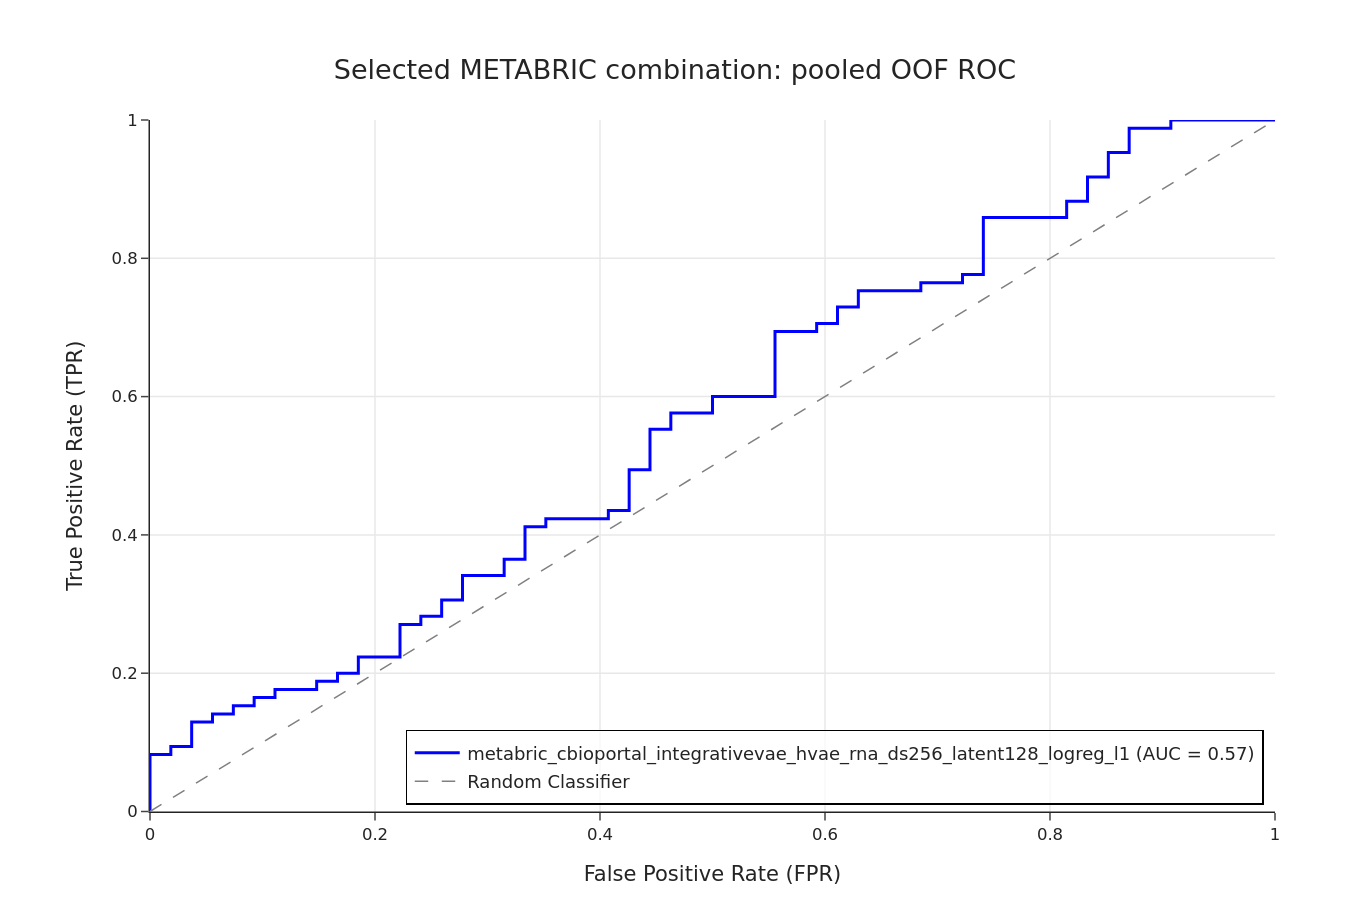

--- Plotting Precision–Recall Curve ---


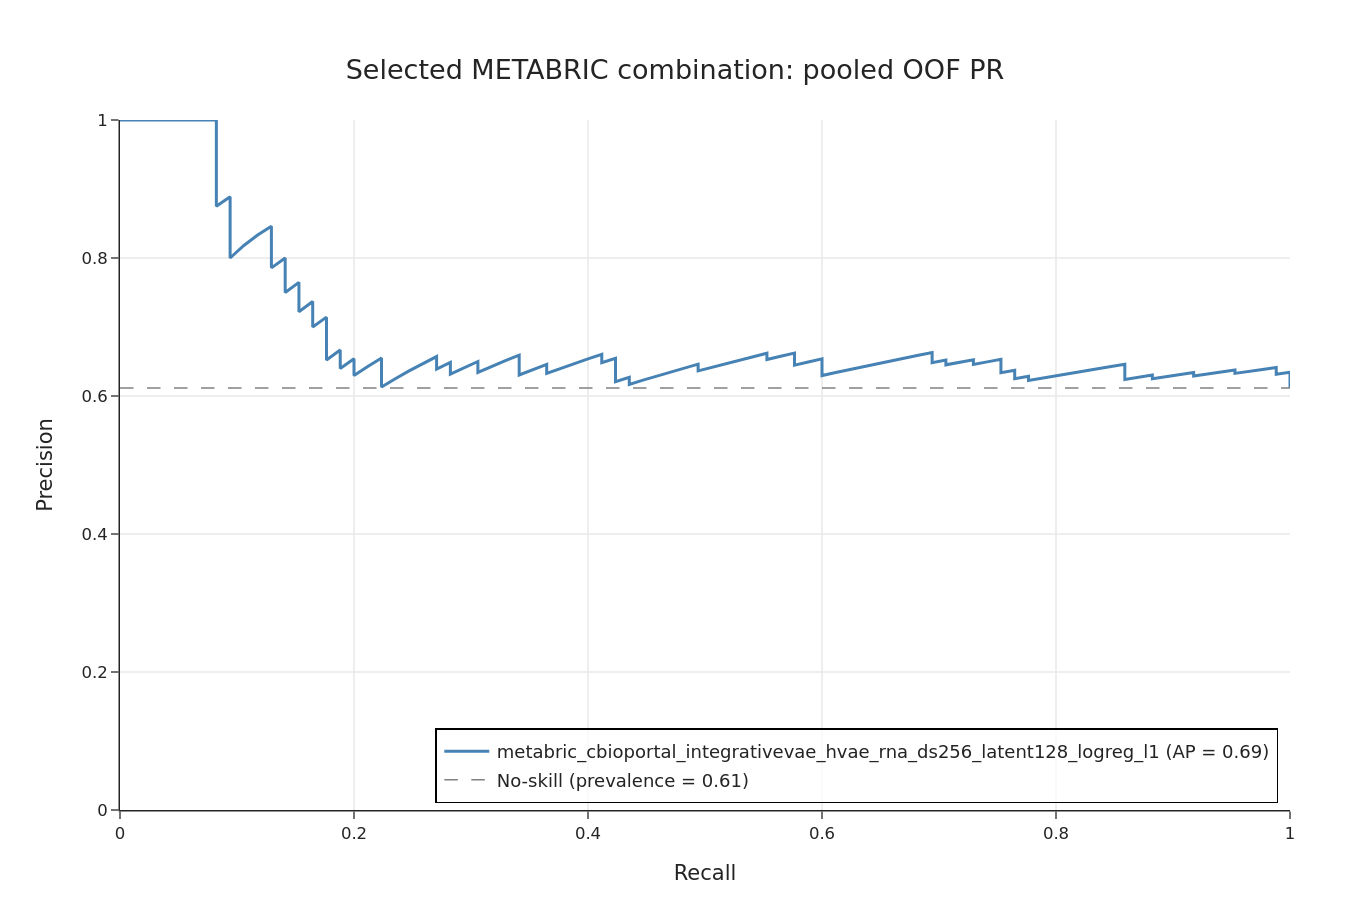

--- Plotting Confusion Matrix ---


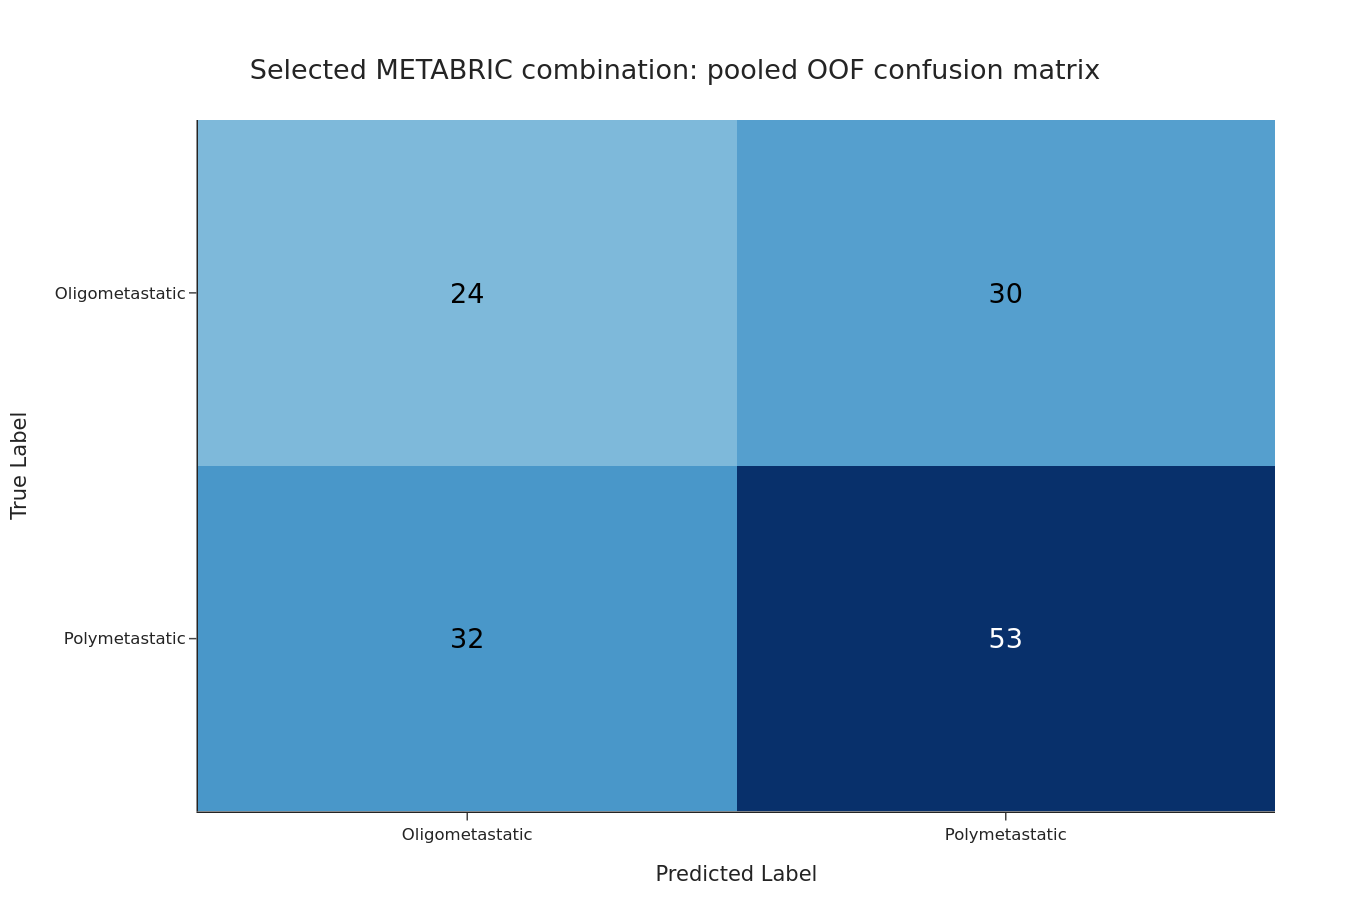

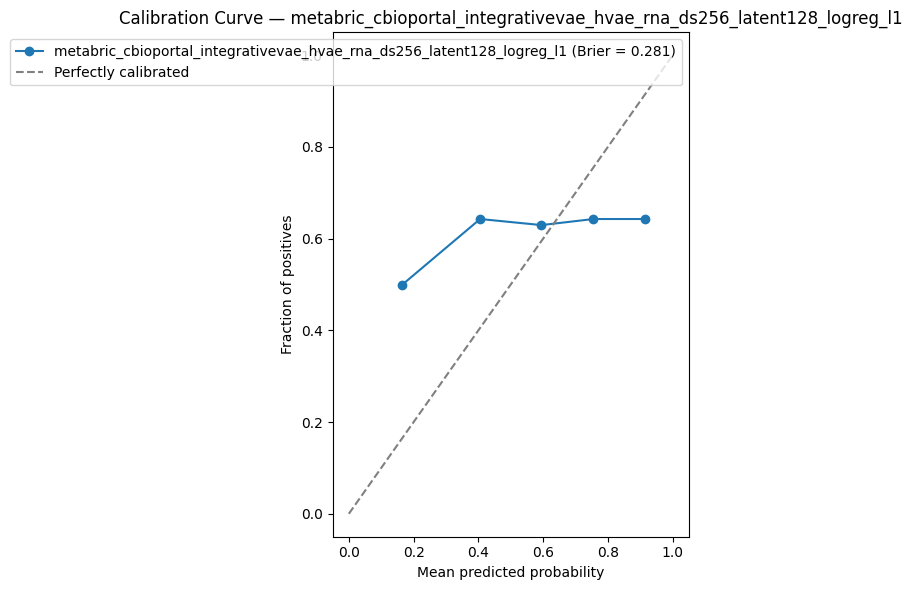

Pooled OOF Brier score: 0.281


In [39]:
if selected_combination is not None:
    selected_predictions_df = validated_oof[selected_combination]
    curve = [{"y_true": selected_predictions_df.y_true.to_numpy(), "y_prob": selected_predictions_df.y_prob_poly.to_numpy(), "label": selected_combination, "is_main_curve": True}]
    plot_roc_curves(curve, title="Selected METABRIC combination: pooled OOF ROC", interactive=False)
    plot_precision_recall_curves(curve, title="Selected METABRIC combination: pooled OOF PR", interactive=False)
    plot_confusion_matrix(selected_predictions_df.y_true, selected_predictions_df.y_pred,
        class_labels=["Oligometastatic", "Polymetastatic"], title="Selected METABRIC combination: pooled OOF confusion matrix", interactive=False)
    brier = plot_calibration_curve(selected_predictions_df.rename(columns={"representation": "model", "y_prob_poly": "y_proba"}), selected_combination, n_bins=5)
    thesis_print("Pooled OOF Brier score:", brier)


## Predictive performance

The selected combination achieved pooled OOF ROC-AUC 0.565359, balanced accuracy 0.533987 and macro-F1 0.533658. Precision was 0.638554 and average precision was 0.687941. These held-out results indicate limited discrimination; average precision must also be interpreted in the context of the cohort's relatively frequent polymetastatic class.

The Brier score of 0.280902 indicates substantial probability error and, alongside the reliability plot, warrants caution about probability quality. Brier score reflects both discrimination and calibration, so it does not isolate calibration error. These results do not justify clinical risk estimation or deployment. The small institutional cohort, compression into a latent representation learned without the oligo/poly target, and microarray-to-RNA-seq domain shift are plausible contributors, but their individual effects were not isolated. The inherited institutional prevalence-filter limitation also remains relevant.


## Exploratory Representation Structure

Full-cohort UMAP coloured by oligo/poly and silhouette scores are descriptive analyses of the two frozen external latent spaces. Neither is held-out predictive evidence or a selection criterion. The execution flag is `RUN_EXPLORATORY=True`. 


In [ ]:
fixed_representations = {}
if X_metabric_integrativevae is not None:
    fixed_representations[REPRESENTATION_NAME] = (X_metabric_integrativevae, y_metabric_integrativevae)
if X_hvae is not None:
    fixed_representations[HVAE_REPRESENTATION_NAME] = (X_hvae, y_hvae)
if RUN_EXPLORATORY:
    if len(fixed_representations) != 2:
        raise ValueError("Both canonical fixed representations are required.")
    silhouette_rows = []
    for name, (features, labels) in fixed_representations.items():
        silhouette_rows.append(compute_representation_silhouette(features, labels, name, scale=True))
        plot_umap_representation(features, labels, name, random_state=RANDOM_STATE, scale=True)
    silhouette_df = pd.DataFrame(silhouette_rows)
    silhouette_df.to_csv(output_dir / "metabric_cbioportal_silhouette_exploratory.csv", index=False)
    thesis_display(silhouette_df)


> **Supplementary FLAML analysis.** These FLAML (AutoML) results are retained as a supplementary analysis and are not reported in the submitted thesis.

## Aligned FLAML Comparator

For each fixed external representation, FLAML uses the same frozen patients, five stratified inner folds, macro-F1 and seed 42. The common budget is **120 seconds per outer fold**. Custom learners include the full existing scaling/sampling/classifier pipelines, so institutional preprocessing is fitted inside FLAML's inner-training process. They search the same three-family latent grids, not an unrestricted default AutoML library. The budget is approximate: a fit already underway may overrun it.

FLAML does not replace the manual mean-inner-score selection. A separate fresh full-cohort FLAML search uses the manually selected representation and the same common budget, exclusively for latent interpretation. No modal outer-fold configuration is used.

FLAML receives an explicit `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` for inner validation, as does the manual search. The same ordered outer-training inputs therefore define the same inner-fold membership in the current implementation; FLAML may permute training-row order within a fold. Saved patient-level predictions confirm identical outer-test assignments. 


In [42]:
flaml_results = {}
if RUN_FLAML and len(fixed_representations) != 2:
    raise ValueError("Both canonical fixed representations are required for aligned FLAML.")
for representation, (features, labels) in fixed_representations.items():
    name = representation + "_flaml"
    paths = [output_dir / f"{name}_{kind}_aligned.csv" for kind in ["nested_test", "nested_train", "oof_predictions"]]
    score_path = latent_scores_path if representation == REPRESENTATION_NAME else hvae_latent_scores_path
    score_fingerprint = metabric_source_fingerprint([score_path])
    flaml_manifest_path = output_dir / f"{name}_provenance_aligned.json"
    if RUN_FLAML:
        test, train, oof = run_nested_flaml_metabric_latent(features, labels, name, metadata_df, outer_splits, FLAML_TIME_BUDGET_SECONDS, RANDOM_STATE)
        for frame, dest in zip([test, train, oof], paths): frame.to_csv(dest, index=False)
        flaml_manifest_path.write_text(json.dumps({"score_source": score_fingerprint}, indent=2))
    elif all(p.exists() for p in paths):
        if json.loads(flaml_manifest_path.read_text()).get("score_source") != score_fingerprint:
            raise ValueError("Cached FLAML results belong to another encoder score file.")
        test, train, oof = [pd.read_csv(p) for p in paths]
    elif any(p.exists() for p in paths):
        raise ValueError("Incomplete aligned FLAML result bundle.")
    else:
        continue
    for frame in [test, train]:
        if len(frame) != 5 or set(frame.outer_fold) != set(range(1, 6)):
            raise ValueError("Five unique FLAML outer-fold results required.")
    protocol = pd.concat([test, train, oof], ignore_index=True)
    if not protocol.inner_n_splits.eq(5).all() or not protocol.selection_metric.eq("macro_f1").all():
        raise ValueError("Saved FLAML protocol is not aligned.")
    if protocol.time_budget_seconds.nunique() != 1 or (FLAML_TIME_BUDGET_SECONDS is not None and not protocol.time_budget_seconds.eq(FLAML_TIME_BUDGET_SECONDS).all()):
        raise ValueError("FLAML budget mismatch.")
    oof = validate_tpm_oof(oof, name, metadata_df, y, outer_splits)
    pooled = {"representation": name, **tpm_pooled_oof_metrics(oof), "mean_inner_cv_score": test.best_inner_score.mean(), "mean_outer_roc_auc": test.roc_auc.mean()}
    pd.DataFrame([pooled]).to_csv(output_dir / f"{name}_pooled_oof_metrics_aligned.csv", index=False)
    flaml_results[representation] = {"test": test, "train": train, "oof": oof, "pooled": pooled}
    flaml_metric_cols = list(tpm_pooled_oof_metrics(oof)) + ["best_inner_score"]
    flaml_fold_summary = pd.concat([train, test]).groupby("dataset")[flaml_metric_cols].agg(["mean", "std"])
    flaml_fold_summary.to_csv(output_dir / f"{name}_fold_metrics_mean_sd_aligned.csv")
    thesis_display(test, train, pd.DataFrame([pooled]), flaml_fold_summary)
if selected_combination is not None and len(flaml_results) == 2:
    manual_comparison = pooled_oof_df.join(summary_df[["mean_inner_cv_score", "mean_test_roc_auc"]]).rename(columns={"mean_test_roc_auc": "mean_outer_roc_auc"})
    comparison = pd.concat([manual_comparison.reset_index(), pd.DataFrame([v["pooled"] for v in flaml_results.values()])], ignore_index=True)
    comparison.to_csv(output_dir / "metabric_cbioportal_manual_vs_flaml_aligned.csv", index=False)
    thesis_display(comparison)


,representation,outer_fold,best_inner_score,best_params,selection_metric,inner_n_splits,time_budget_seconds,dataset,roc_auc,balanced_accuracy,f1_macro,precision,recall,specificity,average_precision,brier_score
0,metabric_cbioportal_integrativevae_rna_only_la...,1,0.468,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,test,0.743,0.642,0.635,0.733,0.647,0.636,0.805,0.224
1,metabric_cbioportal_integrativevae_rna_only_la...,2,0.540,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,test,0.553,0.479,0.464,0.583,0.412,0.545,0.663,0.249
2,metabric_cbioportal_integrativevae_rna_only_la...,3,0.586,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,test,0.353,0.417,0.417,0.533,0.471,0.364,0.531,0.263
3,metabric_cbioportal_integrativevae_rna_only_la...,4,0.506,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,test,0.551,0.521,0.520,0.625,0.588,0.455,0.667,0.249
4,metabric_cbioportal_integrativevae_rna_only_la...,5,0.594,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,test,0.359,0.385,0.386,0.533,0.471,0.300,0.569,0.252


,representation,outer_fold,best_inner_score,best_params,selection_metric,inner_n_splits,time_budget_seconds,dataset,roc_auc,balanced_accuracy,f1_macro,precision,recall,specificity,average_precision,brier_score
0,metabric_cbioportal_integrativevae_rna_only_la...,1,0.468,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,train,0.933,0.837,0.838,0.870,0.882,0.791,0.957,0.191
1,metabric_cbioportal_integrativevae_rna_only_la...,2,0.540,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,train,0.793,0.737,0.725,0.828,0.706,0.767,0.837,0.245
2,metabric_cbioportal_integrativevae_rna_only_la...,3,0.586,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,train,0.951,0.874,0.876,0.899,0.912,0.837,0.965,0.195
3,metabric_cbioportal_integrativevae_rna_only_la...,4,0.506,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,train,0.833,0.723,0.701,0.843,0.632,0.814,0.874,0.246
4,metabric_cbioportal_integrativevae_rna_only_la...,5,0.594,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,train,0.866,0.795,0.789,0.857,0.794,0.795,0.894,0.239


,representation,roc_auc,balanced_accuracy,f1_macro,precision,recall,specificity,average_precision,brier_score,mean_inner_cv_score,mean_outer_roc_auc
0,metabric_cbioportal_integrativevae_rna_only_la...,0.514,0.490,0.487,0.603,0.518,0.463,0.629,0.247,0.539,0.512


roc_auc          balanced_accuracy            f1_macro            \
             mean      std              mean       std      mean       std   
dataset                                                                      
test     0.512  0.162          0.489  0.100  0.484  0.098   
train    0.875  0.066          0.793  0.064  0.786  0.074   

        precision              recall           specificity            \
             mean       std      mean       std        mean       std   
dataset                                                                 
test     0.602  0.083  0.518  0.097    0.460  0.135   
train    0.859  0.027  0.785  0.117    0.801  0.026   

        average_precision           brier_score           best_inner_score  \
                     mean       std        mean       std             mean   
dataset                                                                      
test             0.647  0.106    0.248  0.015         0.539   
train            0.905  0.055    0.223  0.028         0.539   

                   
              std  
dataset            
test     0.053  
train    0.053

,representation,outer_fold,best_inner_score,best_params,selection_metric,inner_n_splits,time_budget_seconds,dataset,roc_auc,balanced_accuracy,f1_macro,precision,recall,specificity,average_precision,brier_score
0,metabric_cbioportal_integrativevae_hvae_rna_ds...,1,0.530,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,test,0.642,0.436,0.386,0.500,0.235,0.636,0.711,0.244
1,metabric_cbioportal_integrativevae_hvae_rna_ds...,2,0.528,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,test,0.535,0.460,0.456,0.579,0.647,0.273,0.690,0.249
2,metabric_cbioportal_integrativevae_hvae_rna_ds...,3,0.619,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,test,0.385,0.356,0.352,0.500,0.529,0.182,0.618,0.252
3,metabric_cbioportal_integrativevae_hvae_rna_ds...,4,0.530,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,test,0.588,0.596,0.594,0.688,0.647,0.545,0.769,0.248
4,metabric_cbioportal_integrativevae_hvae_rna_ds...,5,0.576,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,test,0.488,0.485,0.475,0.615,0.471,0.500,0.647,0.253


,representation,outer_fold,best_inner_score,best_params,selection_metric,inner_n_splits,time_budget_seconds,dataset,roc_auc,balanced_accuracy,f1_macro,precision,recall,specificity,average_precision,brier_score
0,metabric_cbioportal_integrativevae_hvae_rna_ds...,1,0.530,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,train,0.936,0.868,0.860,0.921,0.853,0.884,0.963,0.196
1,metabric_cbioportal_integrativevae_hvae_rna_ds...,2,0.528,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,train,0.888,0.817,0.799,0.911,0.750,0.884,0.928,0.240
2,metabric_cbioportal_integrativevae_hvae_rna_ds...,3,0.619,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,train,0.804,0.742,0.743,0.797,0.809,0.674,0.858,0.244
3,metabric_cbioportal_integrativevae_hvae_rna_ds...,4,0.530,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,train,0.840,0.731,0.728,0.800,0.765,0.698,0.897,0.220
4,metabric_cbioportal_integrativevae_hvae_rna_ds...,5,0.576,"{""best_estimator"": ""metabric_latent_xgboost"", ...",macro_f1,5,120,train,0.825,0.751,0.738,0.842,0.706,0.795,0.873,0.226


,representation,roc_auc,balanced_accuracy,f1_macro,precision,recall,specificity,average_precision,brier_score,mean_inner_cv_score,mean_outer_roc_auc
0,metabric_cbioportal_integrativevae_hvae_rna_ds...,0.510,0.466,0.464,0.581,0.506,0.426,0.653,0.249,0.557,0.528


roc_auc           balanced_accuracy            f1_macro            \
             mean       std              mean       std      mean       std   
dataset                                                                       
test     0.528  0.098          0.467  0.087  0.453  0.094   
train    0.859  0.053          0.782  0.059  0.774  0.056   

        precision              recall           specificity            \
             mean       std      mean       std        mean       std   
dataset                                                                 
test     0.576  0.080  0.506  0.169    0.427  0.192   
train    0.854  0.059  0.776  0.056    0.787  0.099   

        average_precision           brier_score           best_inner_score  \
                     mean       std        mean       std             mean   
dataset                                                                      
test             0.687  0.058    0.249  0.004         0.557   
train            0.904  0.042    0.225  0.019         0.557   

                   
              std  
dataset            
test     0.040  
train    0.040

,representation,roc_auc,balanced_accuracy,f1_macro,precision,recall,specificity,average_precision,brier_score,mean_inner_cv_score,mean_outer_roc_auc
0,metabric_cbioportal_integrativevae_rna_only_la...,0.524,0.587,0.581,0.689,0.600,0.574,0.616,0.277,0.498,0.539
1,metabric_cbioportal_integrativevae_rna_only_la...,0.448,0.504,0.496,0.614,0.729,0.278,0.553,0.254,0.545,0.432
2,metabric_cbioportal_integrativevae_rna_only_la...,0.509,0.496,0.495,0.609,0.659,0.333,0.605,0.248,0.520,0.498
3,metabric_cbioportal_integrativevae_hvae_rna_ds...,0.565,0.534,0.534,0.639,0.624,0.444,0.688,0.281,0.562,0.557
4,metabric_cbioportal_integrativevae_hvae_rna_ds...,0.483,0.457,0.453,0.581,0.635,0.278,0.650,0.248,0.518,0.487
5,metabric_cbioportal_integrativevae_hvae_rna_ds...,0.453,0.473,0.473,0.590,0.576,0.370,0.590,0.251,0.547,0.494
6,metabric_cbioportal_integrativevae_rna_only_la...,0.514,0.490,0.487,0.603,0.518,0.463,0.629,0.247,0.539,0.512
7,metabric_cbioportal_integrativevae_hvae_rna_ds...,0.510,0.466,0.464,0.581,0.506,0.426,0.653,0.249,0.557,0.528


## Interpretation of the FLAML comparison

Under the aligned protocol, FLAML pooled OOF ROC-AUC was 0.514270 for RNA-only scores and 0.509804 for HVAE scores. Neither improved on the selected manual combination's discrimination; both were close to chance. Within this search space and time budget, automated search did not improve discrimination. This is not a claim of uniformly worse performance: FLAML's Brier scores were lower than the selected manual model's. FLAML remains a comparator and does not replace the prespecified selection by mean inner-CV macro-F1.


In [43]:
if RUN_FULL_COHORT_FLAML:
    if selected_combination is None:
        raise ValueError("Freeze manual selection before full-cohort FLAML interpretation.")
    selected_config = metabric_registry[selected_combination]
    representation = selected_config["representation"]
    if representation not in flaml_results or not flaml_results[representation]["test"].time_budget_seconds.eq(FLAML_TIME_BUDGET_SECONDS).all():
        raise ValueError("Load/run aligned nested FLAML using the same common budget first.")
    full_automl = fit_metabric_latent_flaml(selected_config["X"], selected_config["y"], FLAML_TIME_BUDGET_SECONDS, RANDOM_STATE)
    flaml_ranking = extract_fitted_tpm_feature_rankings(full_automl.model.estimator, selected_config["X"].columns)
    flaml_ranking.to_csv(output_dir / f"{representation}_flaml_latent_ranking_full_cohort_tuned.csv", index=False)
    (output_dir / f"{representation}_flaml_params_full_cohort_tuned.json").write_text(json.dumps({
        "best_estimator": full_automl.best_estimator, "best_config": full_automl.best_config,
        "best_inner_score": 1-full_automl.best_loss, "n_splits": 5, "metric": "macro_f1",
        "time_budget_seconds": FLAML_TIME_BUDGET_SECONDS, "interpretation_only": True}, indent=2, default=str))
    display_interpretation(flaml_ranking.head(20))


,feature,importance,feature_score,rank
0,Latent 116,0.0517,0.052,1
1,Latent 48,0.0476,0.048,2
2,Latent 63,0.0455,0.045,3
3,Latent 23,0.0423,0.042,4
4,Latent 97,0.0408,0.041,5
5,Latent 96,0.0408,0.041,6
6,Latent 87,0.0383,0.038,7
7,Latent 99,0.0374,0.037,8
8,Latent 64,0.0368,0.037,9
9,Latent 121,0.0361,0.036,10


## Source Provenance and Scope

The architectures are RNA-only adaptations of [CancerAI-CL/IntegrativeVAEs](https://github.com/CancerAI-CL/IntegrativeVAEs), described in [Simidjievski et al. (2019)](https://doi.org/10.3389/fgene.2019.01205), not a reproduction of the complete multimodal framework. Institutional sources are `rnaseq_tpm_norm.txt` and `TPM_prim_polymets_ALL.tsv`, documented in `20260707-preprocessing-tpm-oligopolypatients.ipynb`; their processed matrix and cached mapping are retained unchanged.

Source manifests and cohort/fold identifiers distinguish the full cBioPortal experiment from reduced-source analyses. Cross-platform differences and the inherited institutional prevalence-filter limitation remain relevant to interpretation.


## Gene-level Integrated Gradients

For either external representation, a selected L1 logistic regression allows the polymetastatic probability to be attributed through frozen external preprocessing, the deterministic latent-mean encoder in inference mode, and fitted downstream scaling and logistic coefficients. This analysis requires completed nested-CV selection and a fresh full-cohort interpretation refit; it never selects models.

The reference is each gene's METABRIC training-partition mean on the supplied log-expression scale, not biological absence of expression. RNA-only StandardScaler maps this mean approximately to zero. HVAE uses its exact frozen min–max transformation: the transformed reference is (training mean − training minimum) / training range, generally not zero. No institutional statistics define either baseline.

Only the 1,000 model-facing genes receive direct attribution. Signed and absolute patient-level IG, cohort summaries, Ensembl IDs and gene symbols are saved with probability-agreement, completeness and integration-convergence diagnostics. Genes outside this set are not necessarily biologically unimportant.

For RF/XGBoost, downstream SHAP/native importance remains in latent space. Optional IG targets explicitly named latent coordinates and is representation attribution, not polymetastatic-risk attribution. Gene IG, latent importance and biological association are distinct and non-causal. Outputs are published in a new validated interpretation directory only after numerical checks pass; failed diagnostics remain in a separate pending directory.


In [44]:
final_interpretation_model = None
if RUN_INTEGRATED_GRADIENTS:
    if selected_combination is None or final_interpretation_model is None:
        restored_selection, restored_config, restored_model = restore_metabric_ig_l1_model(
            output_dir, metadata_df, y, outer_splits, source_paths)
        if selected_combination is not None and selected_combination != restored_selection:
            raise ValueError('In-memory and saved canonical selection disagree')
        selected_combination = restored_selection
        metabric_registry[selected_combination] = restored_config
        final_interpretation_model = restored_model
    ig_config = metabric_registry[selected_combination]
    ig_representation = ig_config['representation']
    if ig_representation == REPRESENTATION_NAME:
        ig_kind, ig_completed = 'rna', rna_completed_dir
    elif ig_representation == HVAE_REPRESENTATION_NAME:
        ig_kind, ig_completed = 'hvae', hvae_completed_dir
    else:
        raise ValueError('Unknown canonical representation')
    ig_output_path = run_metabric_vae_ig(ig_config, final_interpretation_model, ig_completed,
        ig_representation, ig_kind, output_dir, source_paths, gene_mapping_path)
    thesis_print('Validated interpretation output:', ig_output_path)


Validated interpretation output: /mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/Transcriptomics-Representation-Learning/METABRIC-IntegrativeVAE/cBioPortal-reviewed/canonical-16950/Original-HVAE-RNA-Branch/metabric_cbioportal_integrativevae_hvae_rna_ds256_latent128_completed/interpretation_ig/validated_b15b550f20dc41c987d10a022cea27ae


quantity,value
representation,metabric_cbioportal_integrativevae_hvae_rna_ds256_latent128
family,logreg_l1
preparation_fingerprint,e33634913c125cc3ecf7891c31e04bd84af7f0258eff9012dbac3d66d55eed91
baseline,METABRIC external training mean in supplied log-expression space
external_transform,hvae
max_latent_difference,6.40e-6
max_probability_difference,2.92e-6


steps,max_absolute_completeness_residual,mean_absolute_change
64,0.005,NaN
128,0.001,2.16e-6
256,2.29e-4,5.43e-7


gene_name,mean_absolute_ig,mean_signed_ig
ISG20,0.060,0.060
CCL3L3,0.042,-0.042
CTXN1,0.040,-0.040
INSM1,0.039,-0.039
GIMAP7,0.039,-0.039
NLRP8,0.038,-0.038
ADAMDEC1,0.038,-0.038
RAMP1,0.037,0.037
RGMA,0.035,-0.035
F12,0.035,0.035


## Integrated Gradients interpretation

Integrated Gradients (IG) attributes the fresh full-cohort HVAE + L1 model's predicted P(polymetastatic = 1) to its 1,000 gene-expression inputs through the frozen external transformation and latent-mean encoder. The reference is the METABRIC training mean in supplied log-expression space. Mean absolute IG ranks the magnitude of contributions across patients; mean signed IG describes their average direction and can conceal opposing patient-level effects. These are interpretation-only summaries of the fitted model, not held-out performance estimates.

ISG20, CCL3L3, CTXN1, INSM1 and GIMAP7 lead the mean-absolute ranking. Positive mean signed contributions include ISG20, RAMP1, F12, VCAM1, MAFA, ANTXR1, CD79B and C1QC; negative contributions include CCL3L3, CTXN1, INSM1, GIMAP7, NLRP8, ADAMDEC1, RGMA, PLAAT3, PTTG1, TMEM158, HSPA2 and SERPINE2. Positive values indicate contributions toward higher predicted polymetastatic probability relative to the external baseline; negative values indicate the opposite. Neither direction establishes an independent expression–outcome association, a monotonic effect of increasing expression, or causality.

Numerical agreement supported the implemented attribution path: maximum latent and probability differences were approximately 6.4e-06 and 2.9e-06, respectively. The maximum absolute completeness residual decreased from 0.004616 at 64 integration steps to 0.000229 at 256 steps. These checks support numerical fidelity, not predictive validity or biological relevance.

Two leading genes have directly relevant breast-cancer literature. VCAM1 has been studied in macrophage–tumour-cell interactions and survival of breast cancer cells in the lung ([Chen et al., 2011, *Cancer Cell*](https://doi.org/10.1016/j.ccr.2011.08.025)). SERPINE2 was investigated in relation to vascular mimicry and metastatic dissemination in mammary tumour models, with supporting experiments in human breast cancer cell lines ([Wagenblast et al., 2015, *Nature*](https://doi.org/10.1038/nature14403)). These studies provide biological context rather than evidence about oligo/poly classification in this cohort. In particular, SERPINE2's negative signed IG is a baseline-relative model contribution and should not be interpreted as evidence of a protective biological role. Neither study validates this model or its gene ranking.


## Scientific interpretation

HVAE latent128 + L1 was selected by inner-CV macro-F1, but held-out predictive performance remained modest. This experiment does not show a strong predictive advantage for the external HVAE representation, nor, without a direct matched comparison, superiority over simpler transcriptomic representations. The full-cohort model and IG ranking offer exploratory biological hypotheses and a gene-level view of model behaviour, rather than a clinically useful classifier. Independent validation is required before interpreting these priorities as reproducible findings.
